<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Quantify cell-like vs. high-density uRNA and their overlap across samples and segmentations.
> - **Manuscript panels:** Fig. 2A-B, ED Fig. 2D-F
> - **Inputs:** `data_with_source_score.zarr` of every dataset/segmentation
> - **Outputs:** `*_proportions.pdf`, `urna_quadrant_composition.pdf`
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

Quantify cell-like proportions 

# Import modules

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
import os

from troutpy_reproducibility.batch_running import *
from troutpy_reproducibility.downstream import *

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
from troutpy import pl
from troutpy import tl
from troutpy import pp


In [3]:
saving_path='/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general'
os.makedirs(saving_path, exist_ok=True)


Processing: rois/xenium_hsputamen


version mismatch: detected: RasterFormatV02, requested: FormatV04


version mismatch: detected: RasterFormatV02, requested: FormatV04


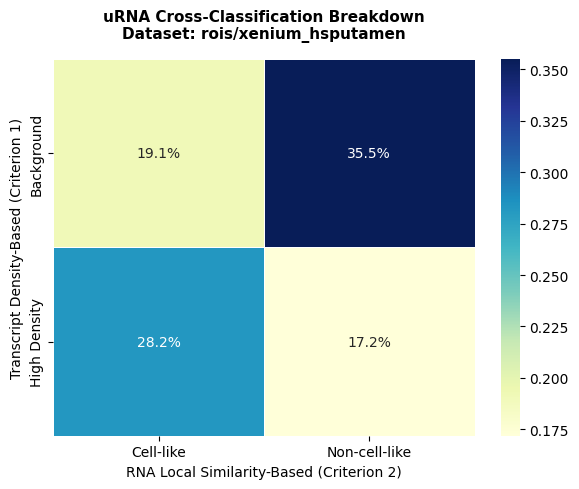

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois/xenium_msbrain_5k


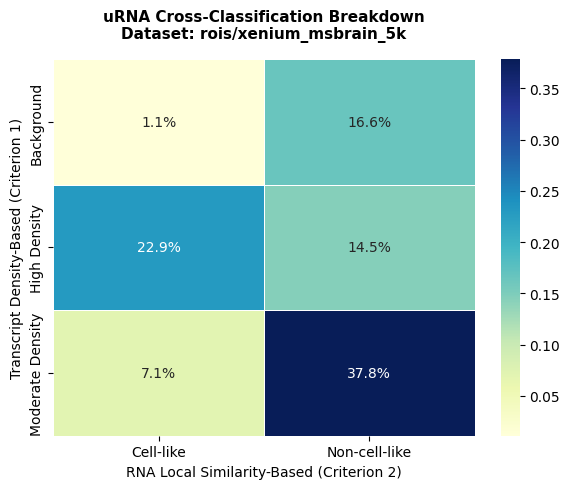

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois/cosmx_hgsoc


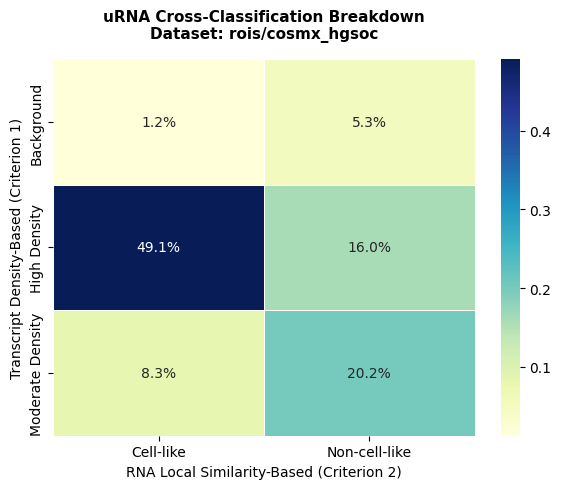


Processing: rois/xenium_opsc_5k


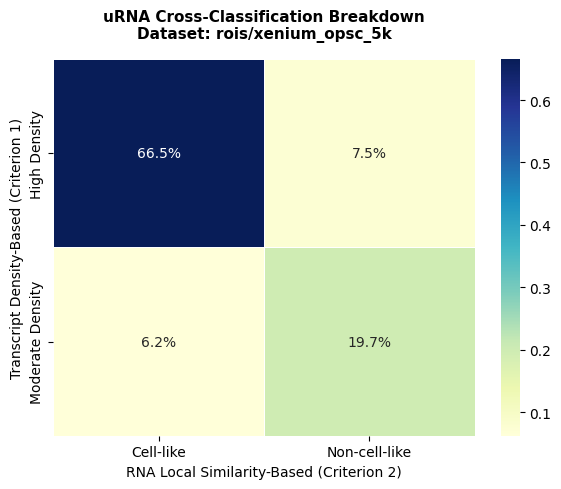

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois/cosmx_mousebrain


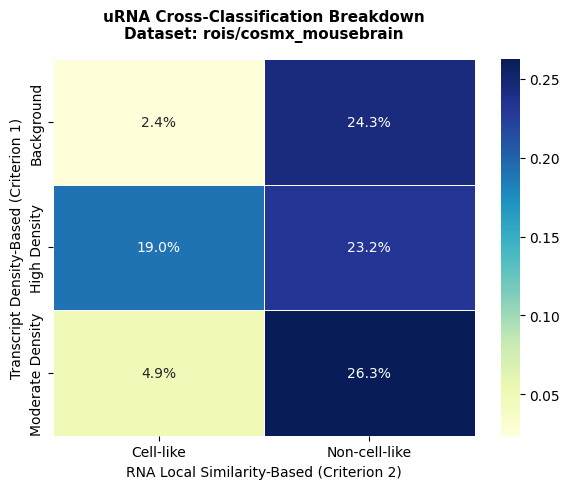


Processing: rois/merscope_hsbrain


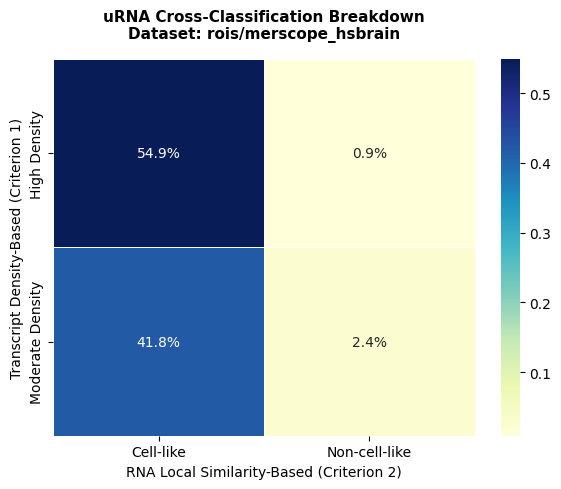

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois/xenium_hsfemur


version mismatch: detected: RasterFormatV02, requested: FormatV04


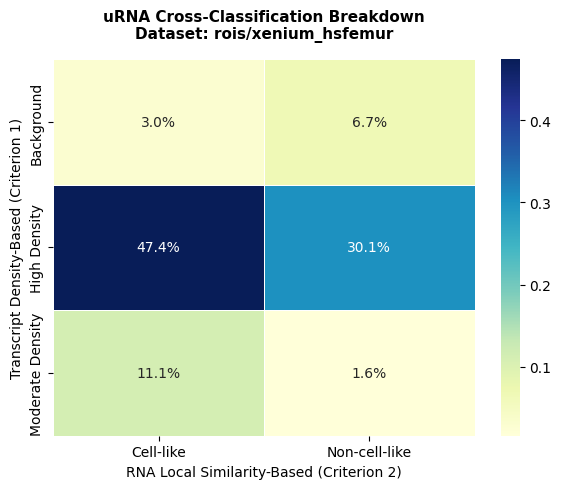

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois/cosmx_melanoma


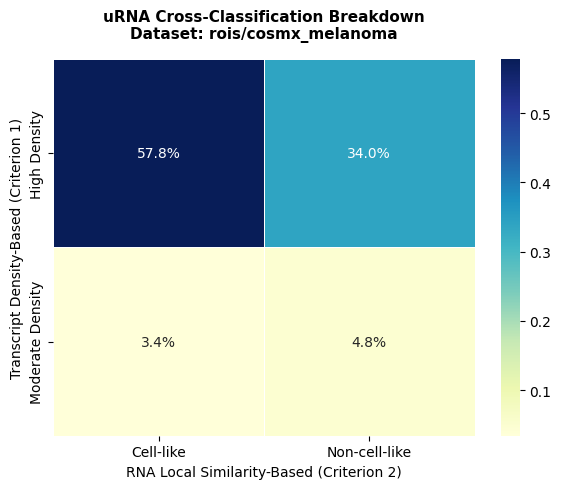


Processing: rois/xenium_hsheart


version mismatch: detected: RasterFormatV02, requested: FormatV04


version mismatch: detected: RasterFormatV02, requested: FormatV04


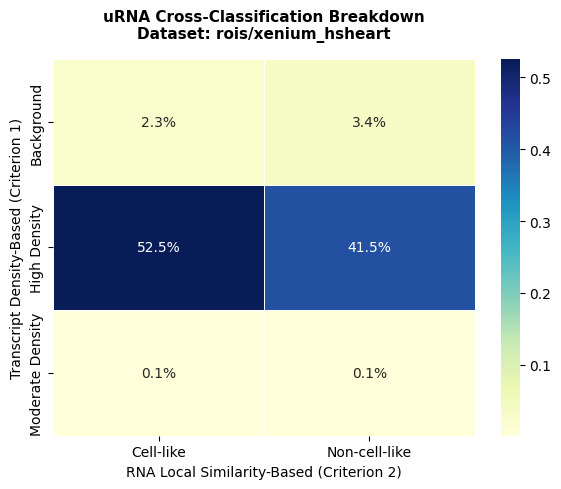

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois/xenium_hsskin_5k


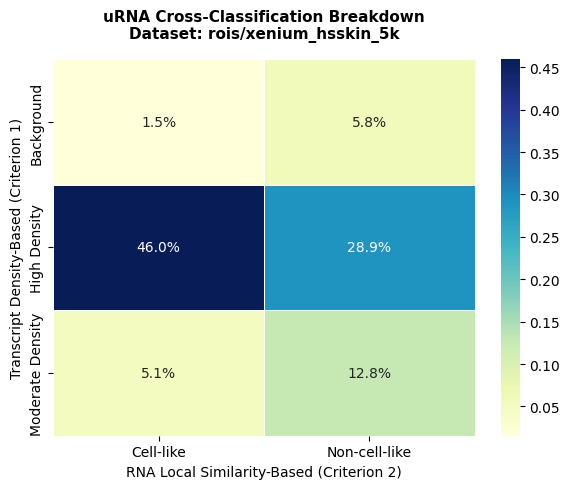


Processing: rois/xenium_mscolon_5k


version mismatch: detected: RasterFormatV02, requested: FormatV04


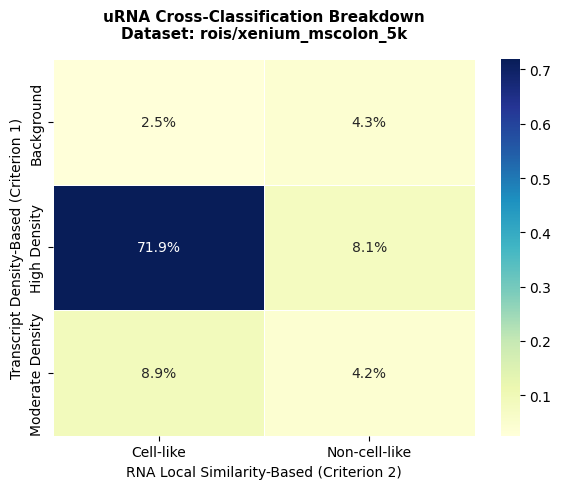


Processing: rois/atera_hsbreast


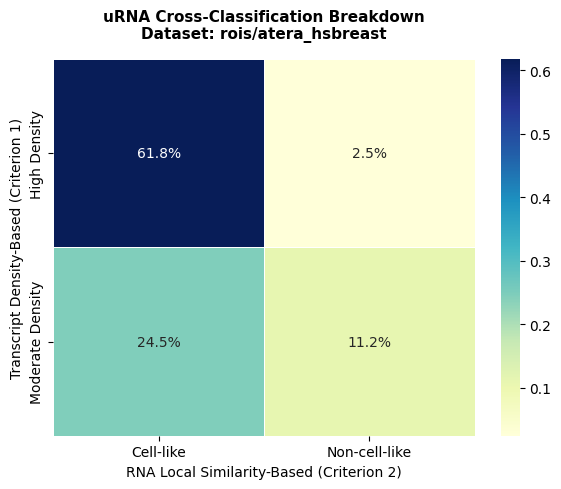


Processing: rois/merscope_hsuterine


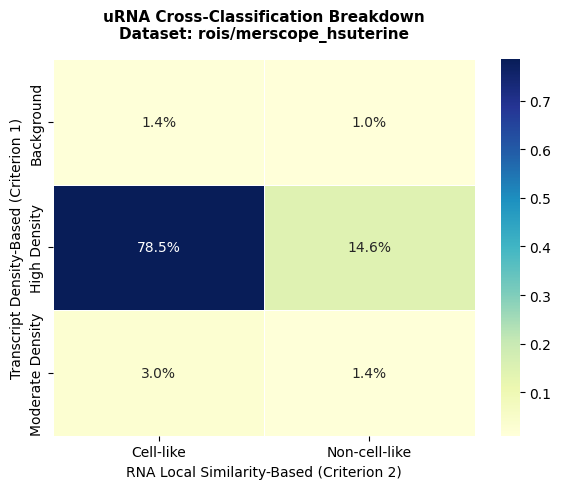

Path does not exist
Path does not exist

Processing: rois/xenium_msbrain_300


version mismatch: detected: RasterFormatV02, requested: FormatV04


version mismatch: detected: RasterFormatV02, requested: FormatV04


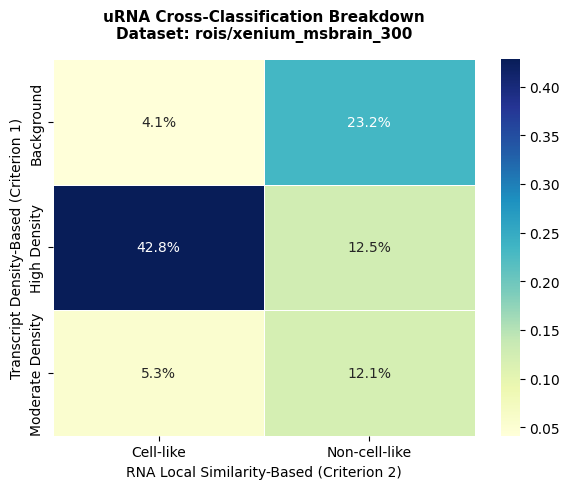


Processing: rois/cosmx_stomach


version mismatch: detected: RasterFormatV02, requested: FormatV04


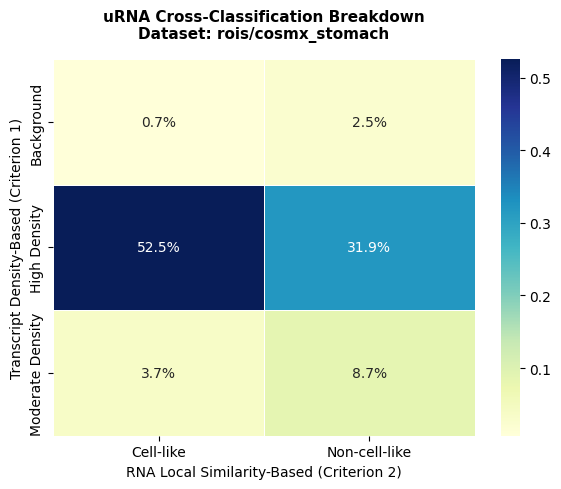


Processing: rois/xenium_opsc_v1


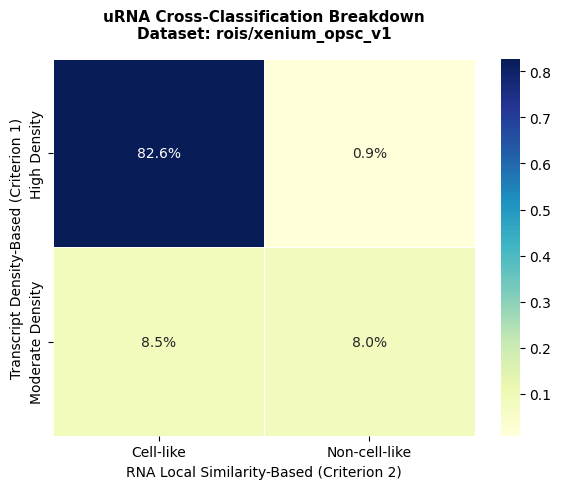

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois/xenium_hsprostate


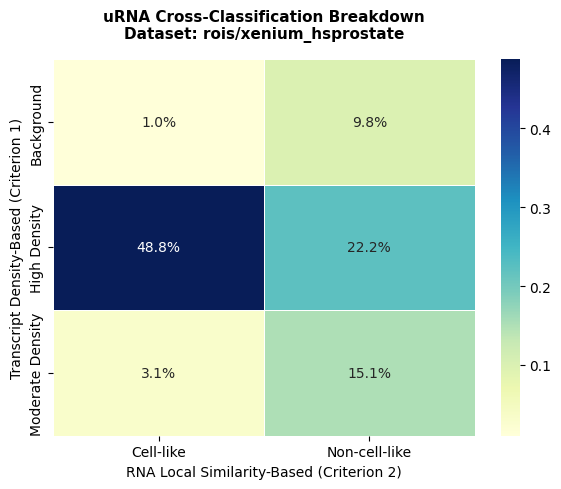

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_proseg/xenium_hsputamen


version mismatch: detected: RasterFormatV02, requested: FormatV04


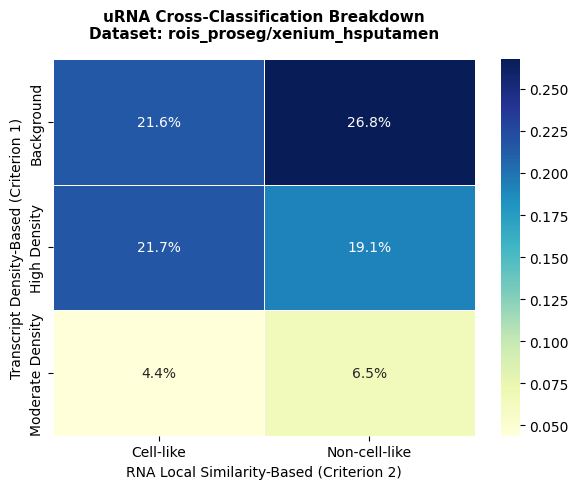


Processing: rois_proseg/xenium_msbrain_5k


version mismatch: detected: RasterFormatV02, requested: FormatV04


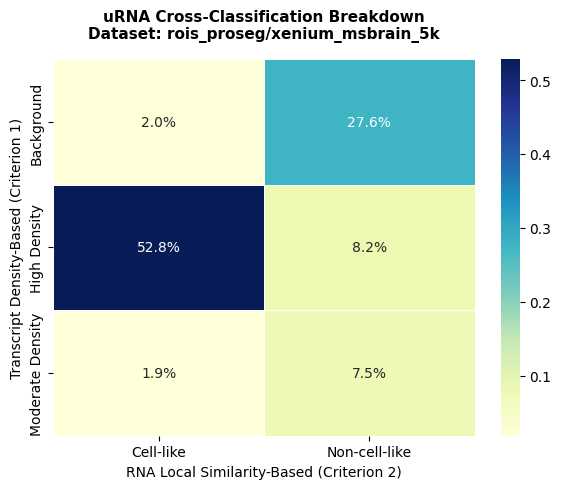


Processing: rois_proseg/cosmx_hgsoc


version mismatch: detected: RasterFormatV02, requested: FormatV04


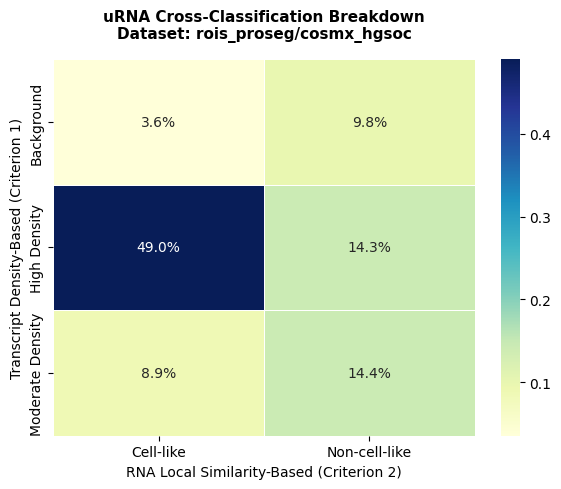


Processing: rois_proseg/xenium_opsc_5k


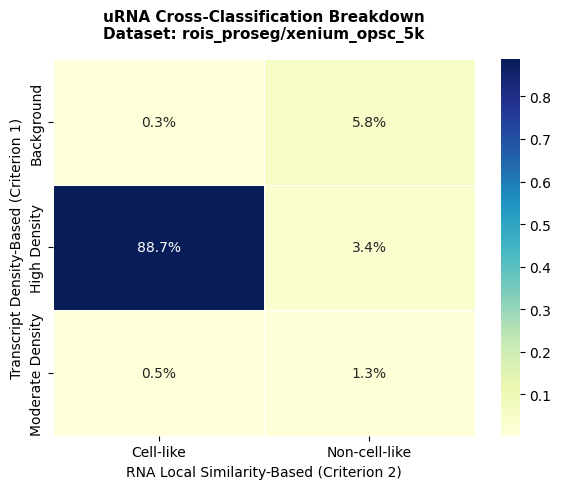

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_proseg/cosmx_mousebrain


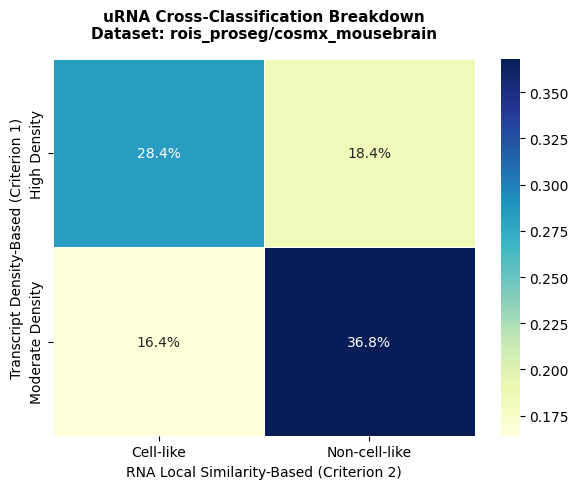

Path does not exist

Processing: rois_proseg/merscope_hsbrain


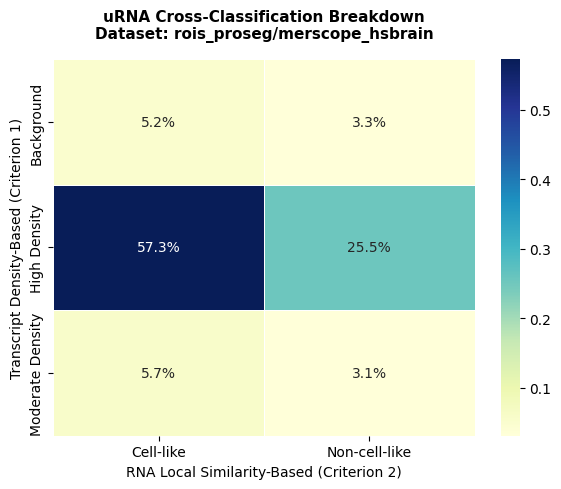

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_proseg/xenium_hsfemur


version mismatch: detected: RasterFormatV02, requested: FormatV04


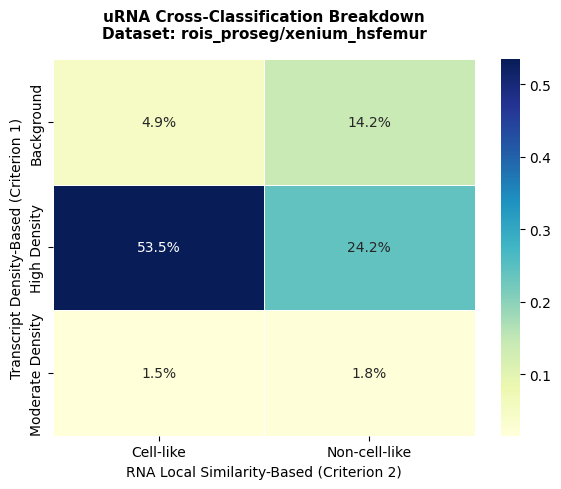

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_proseg/cosmx_melanoma


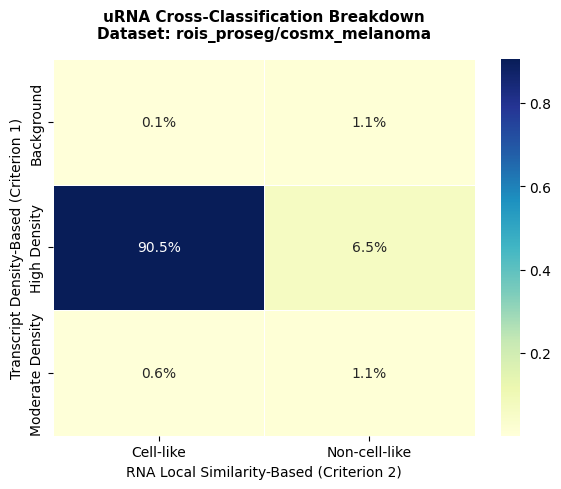


Processing: rois_proseg/xenium_hsheart


version mismatch: detected: RasterFormatV02, requested: FormatV04


version mismatch: detected: RasterFormatV02, requested: FormatV04


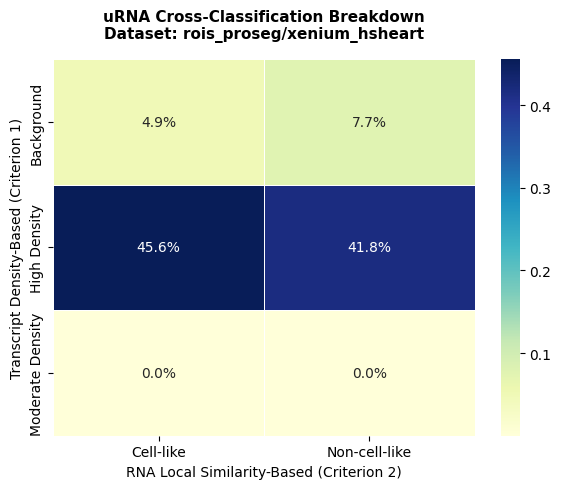

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_proseg/xenium_hsskin_5k


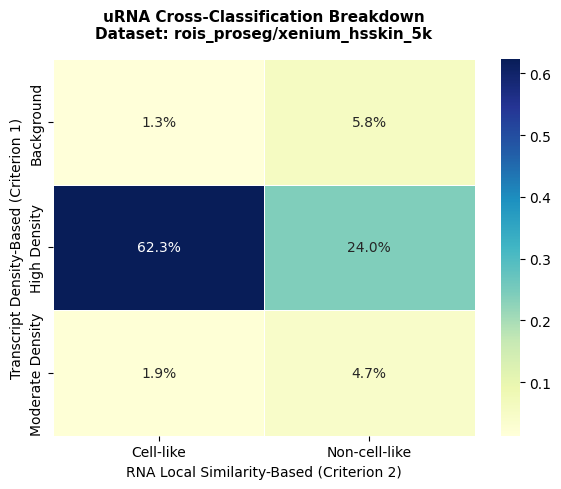

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_proseg/xenium_mscolon_5k


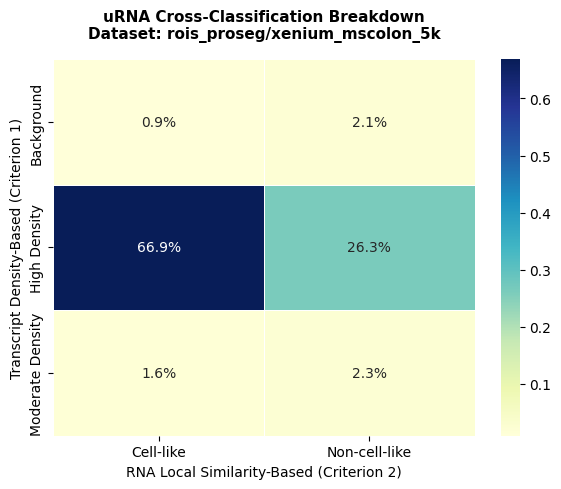


Processing: rois_proseg/atera_hsbreast


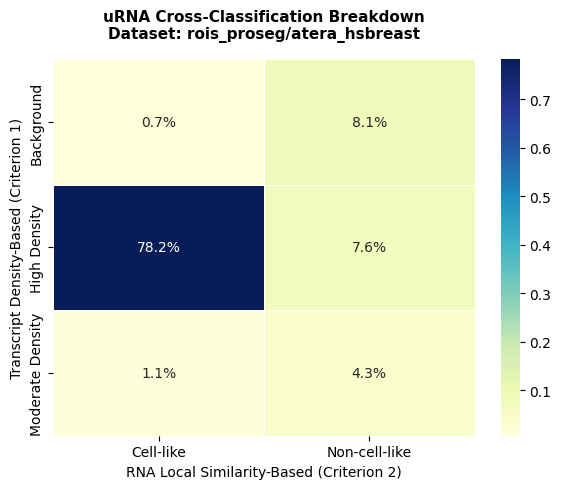

Path does not exist

Processing: rois_proseg/merscope_hsuterine


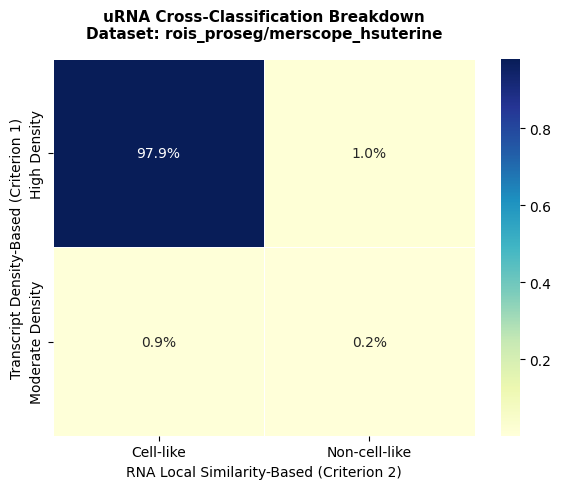

Path does not exist
Path does not exist
Path does not exist

Processing: rois_proseg/xenium_msbrain_300


version mismatch: detected: RasterFormatV02, requested: FormatV04


version mismatch: detected: RasterFormatV02, requested: FormatV04


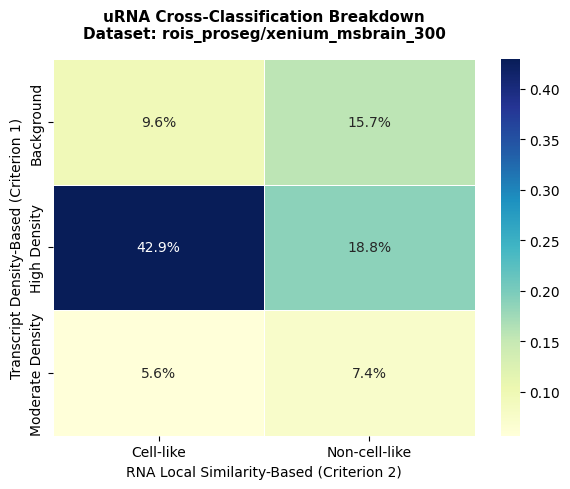

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_proseg/cosmx_stomach


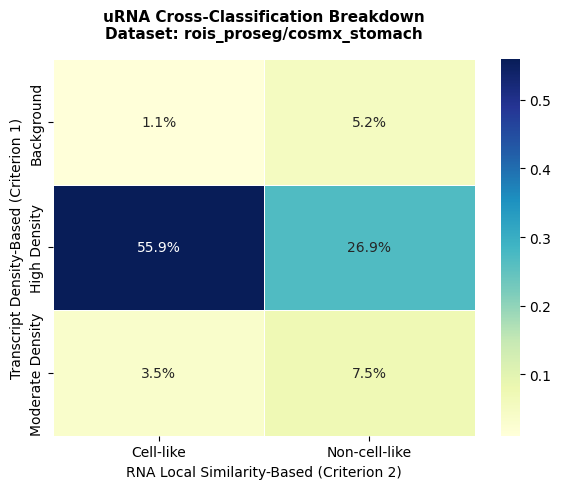


Processing: rois_proseg/xenium_opsc_v1


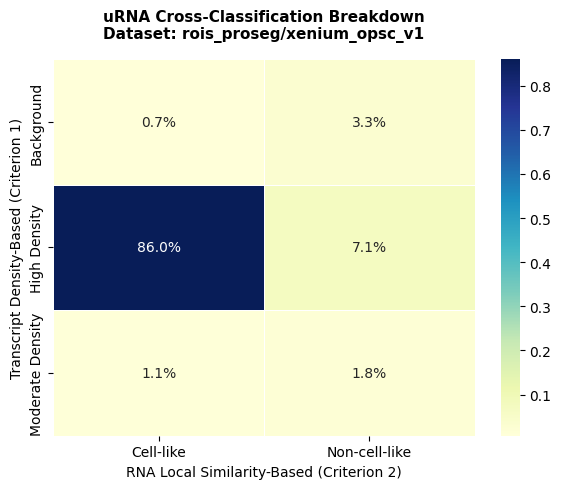

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_proseg/xenium_hsprostate


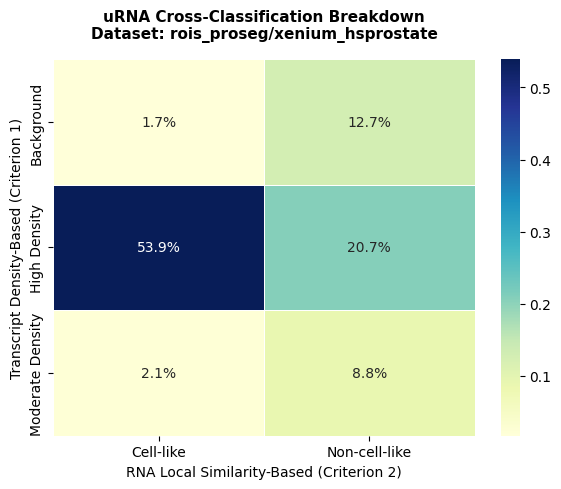


Processing: rois_segger/xenium_opsc_5k


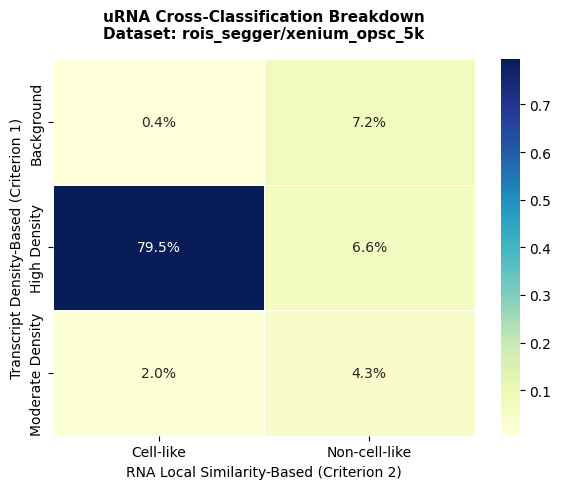

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_segger/xenium_hsputamen


version mismatch: detected: RasterFormatV02, requested: FormatV04


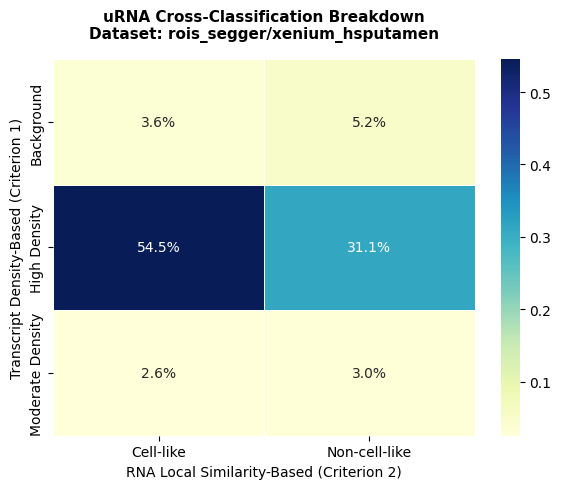

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_segger/xenium_hsheart


version mismatch: detected: RasterFormatV02, requested: FormatV04


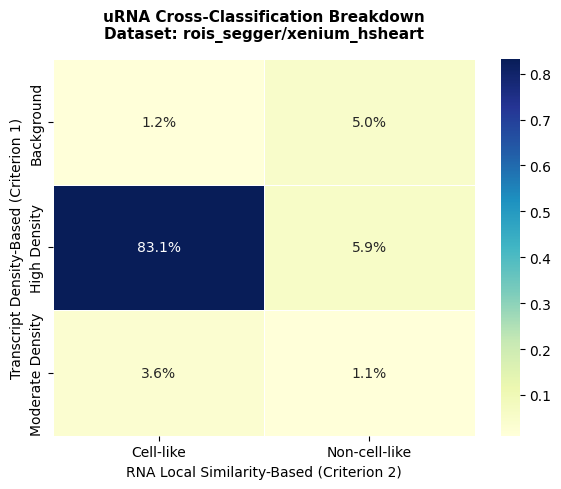

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_segger/xenium_mscolon_5k


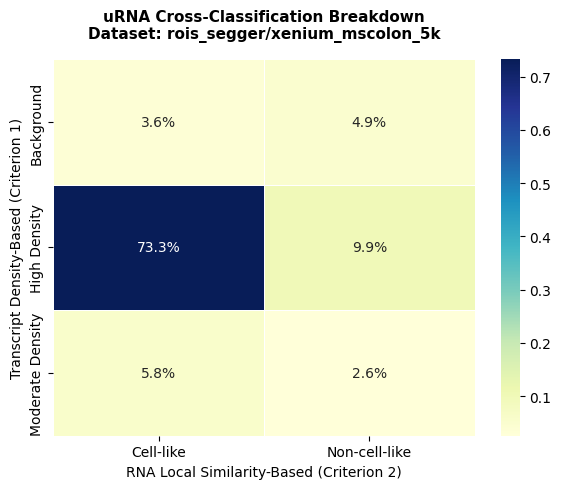


Processing: rois_segger/xenium_hsskin_5k


version mismatch: detected: RasterFormatV02, requested: FormatV04


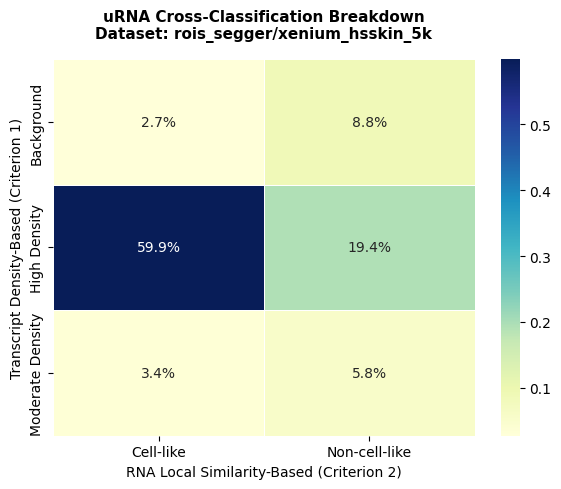


Processing: rois_segger/xenium_hsprostate


version mismatch: detected: RasterFormatV02, requested: FormatV04


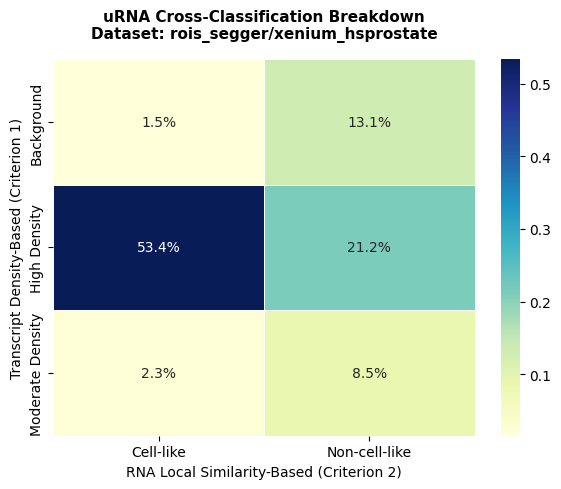

Path does not exist

Processing: rois_segger/xenium_opsc_v1


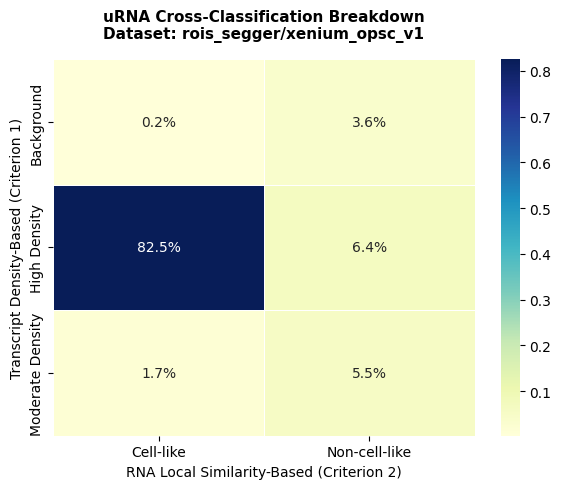

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_segger/xenium_msbrain_5k


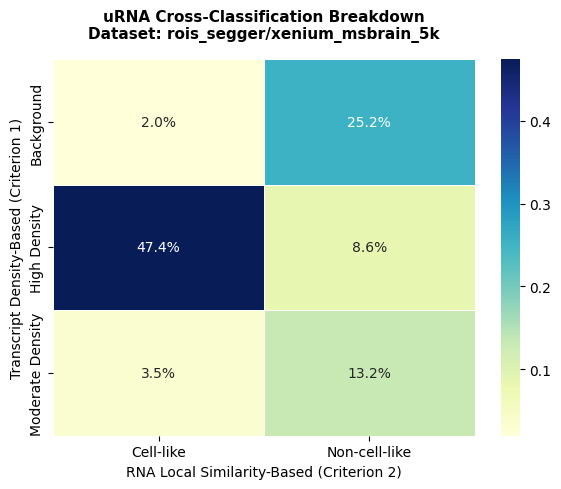


Processing: rois_segger/atera_hsbreast


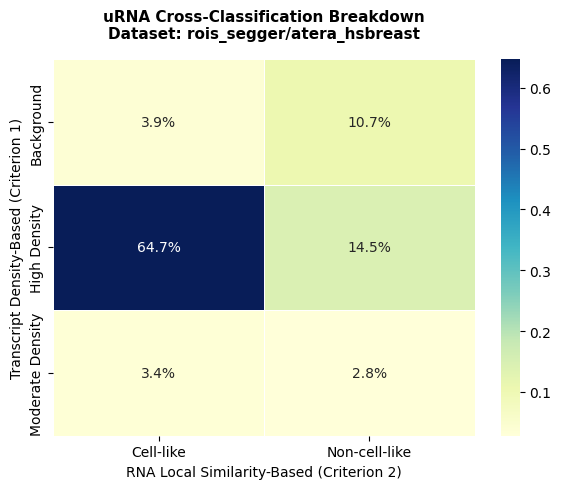


Processing: rois_segger/cosmx_hgsoc


version mismatch: detected: RasterFormatV02, requested: FormatV04


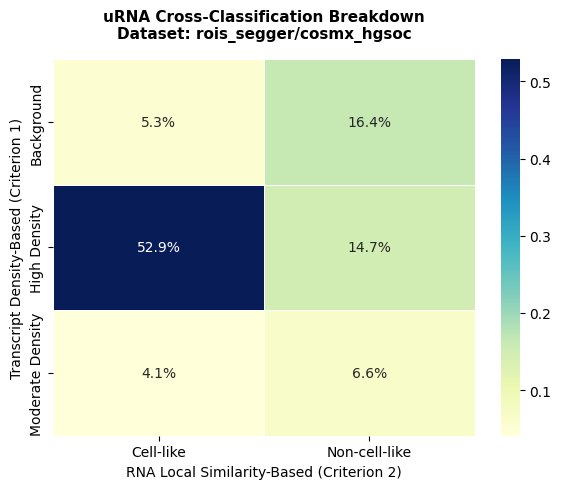

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_segger/cosmx_mousebrain


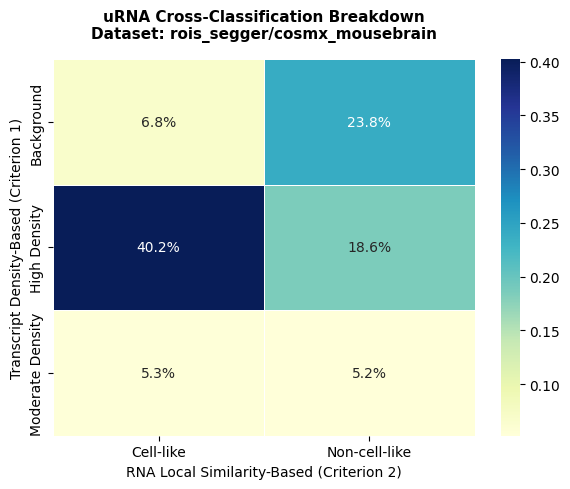

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_segger/xenium_hsfemur


version mismatch: detected: RasterFormatV02, requested: FormatV04


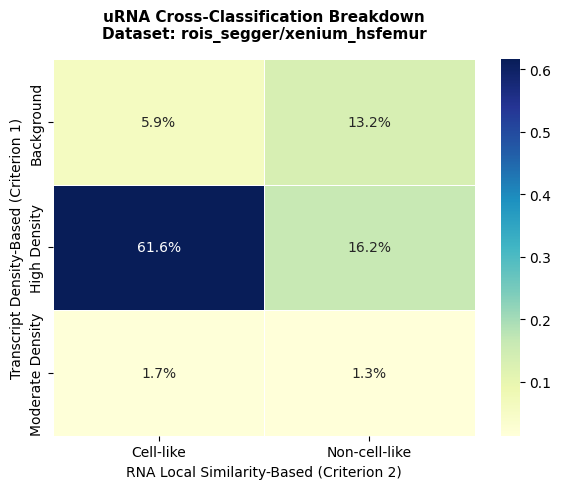

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_segger/cosmx_melanoma


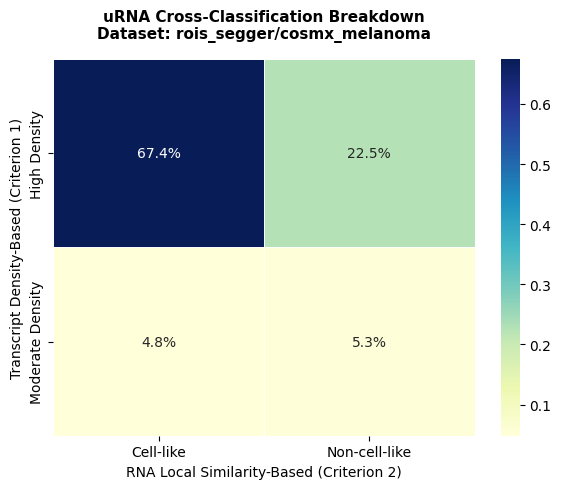


Processing: rois_segger/merscope_hsbrain


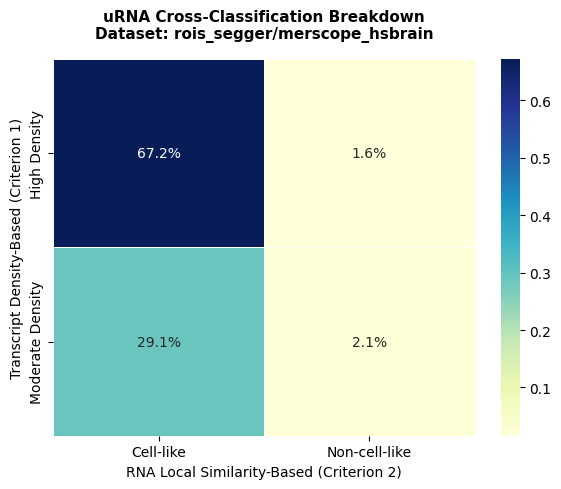


Processing: rois_segger/merscope_hsuterine


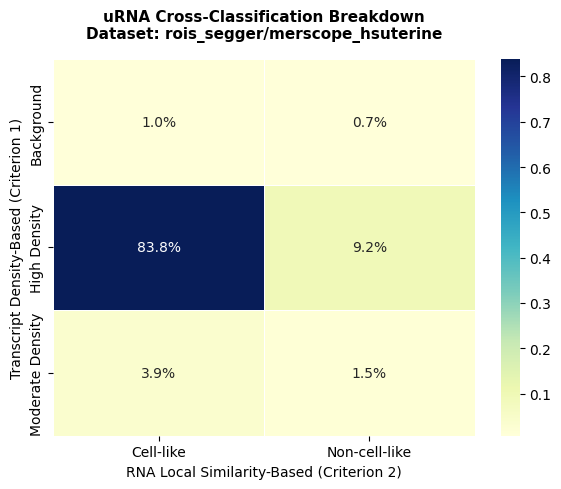

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_segger/cosmx_stomach


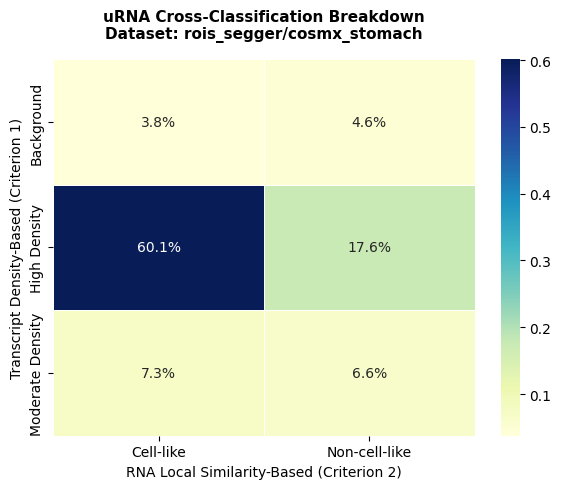

version mismatch: detected: RasterFormatV02, requested: FormatV04



Processing: rois_segger/xenium_msbrain_300


version mismatch: detected: RasterFormatV02, requested: FormatV04


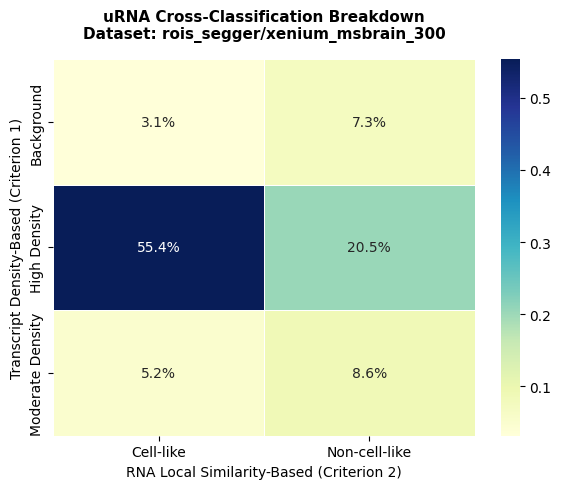

In [4]:
base_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/"
segmentations = ["rois", "rois_proseg", "rois_segger"]

# Samples to exclude from all downstream analysis/plots
excluded_samples = {"xenium_rcc", "cosmx_pancreas"}

all_dataset_counts = {}

for seg in segmentations:
    root_dir = os.path.join(base_dir, seg)
    if not os.path.exists(root_dir):
        continue
        
    subfolders = [f.name for f in os.scandir(root_dir) if f.is_dir()]#[0:10]
    
    for subfolder in subfolders:
        if subfolder in excluded_samples:
            continue

        zarr_path = os.path.join(root_dir, subfolder, 'data_processed_full.zarr')
        unique_key = f"{seg}/{subfolder}"
        
        if os.path.exists(zarr_path):
            print(f"\nProcessing: {unique_key}")
            try:
                sdata = sd.read_zarr(zarr_path)
                
                # Run and harvest counts
                c1, c2, c_all = process_transcript_classifications(sdata, dataset_name=unique_key)
                
                # Store data
                all_dataset_counts[unique_key] = {
                    'Crit1_Density': c1,
                    'Crit2_Similarity': c2,
                    'Combined_Criteria': c_all
                }
                
            except ValueError as ve:
                if "version mismatch" in str(ve).lower() or "format" in str(ve).lower():
                    print(f"Skipping {unique_key} due to breaking SpatialData format mismatch: {ve}")
                else:
                    print(f"Value Error processing {unique_key}: {ve}")
            except Exception as e:
                print(f"General Error processing {unique_key}: {e}")
        else:
            print('Path does not exist')


Plotting normalized maps for rois...


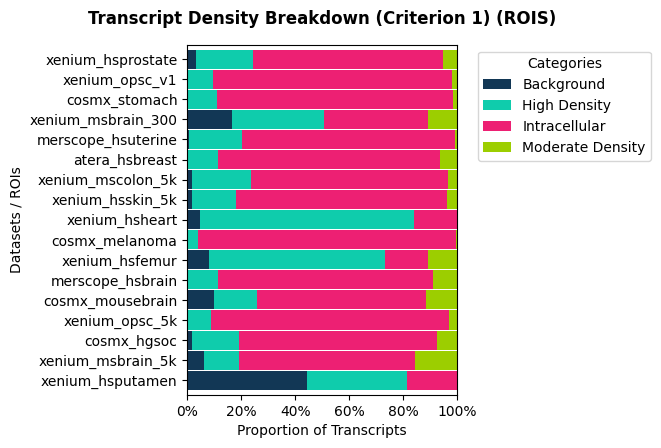

Saved normalized plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/rois_Crit1_Density_proportions.pdf


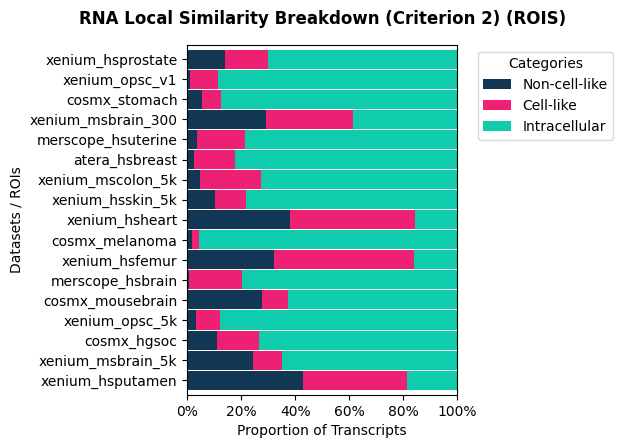

Saved normalized plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/rois_Crit2_Similarity_proportions.pdf


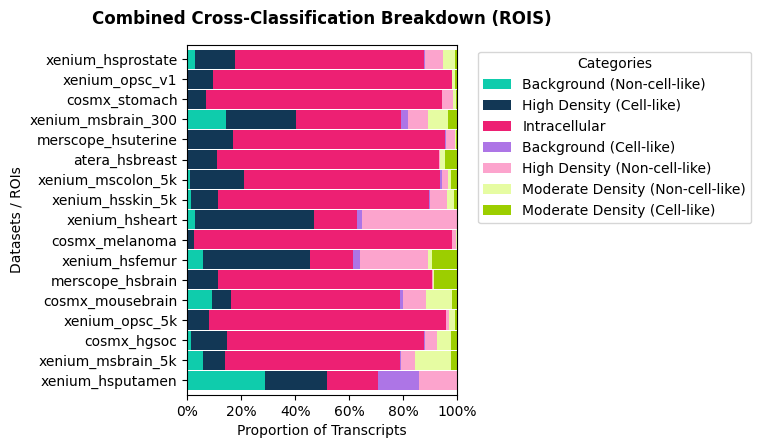

Saved normalized plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/rois_Combined_Criteria_proportions.pdf

Plotting normalized maps for rois_proseg...


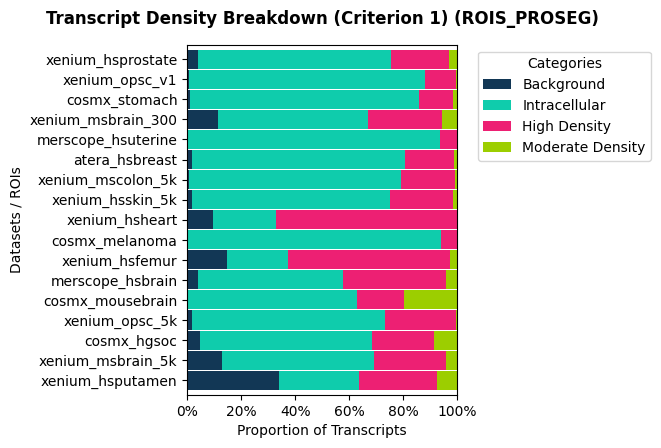

Saved normalized plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/rois_proseg_Crit1_Density_proportions.pdf


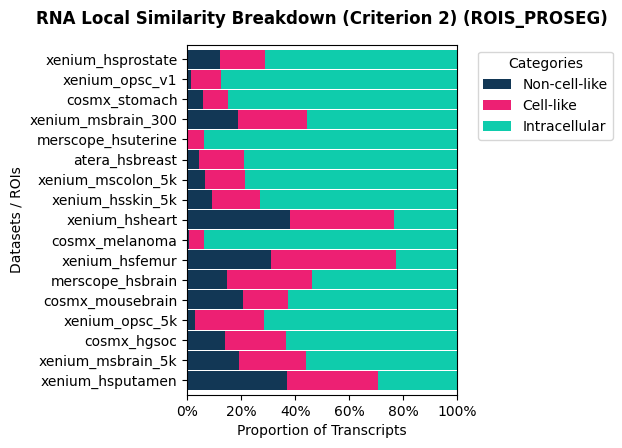

Saved normalized plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/rois_proseg_Crit2_Similarity_proportions.pdf


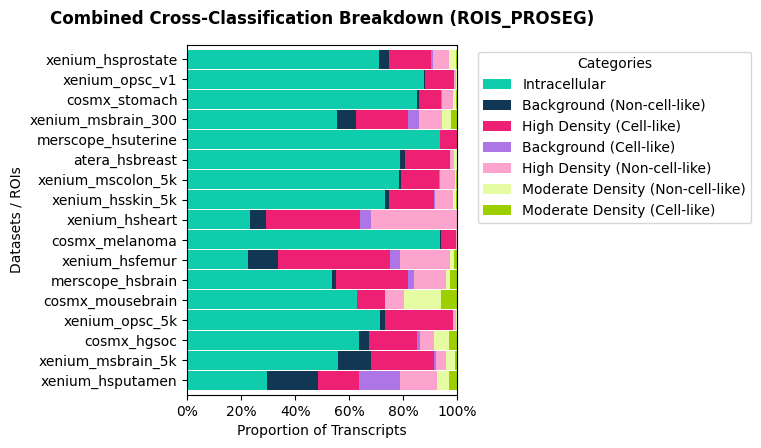

Saved normalized plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/rois_proseg_Combined_Criteria_proportions.pdf

Plotting normalized maps for rois_segger...


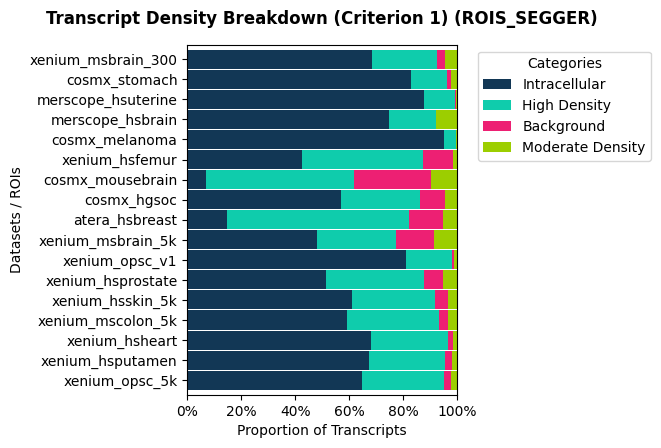

Saved normalized plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/rois_segger_Crit1_Density_proportions.pdf


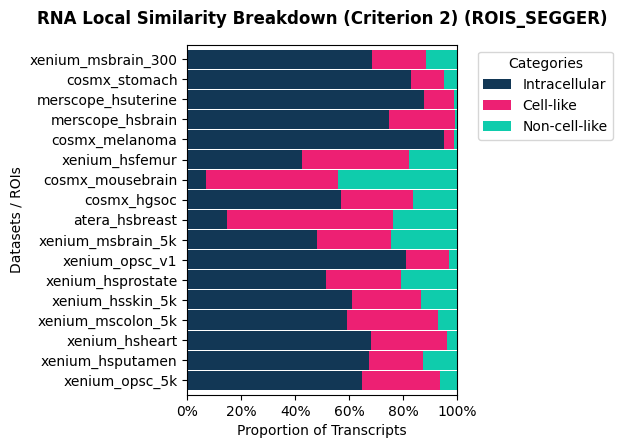

Saved normalized plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/rois_segger_Crit2_Similarity_proportions.pdf


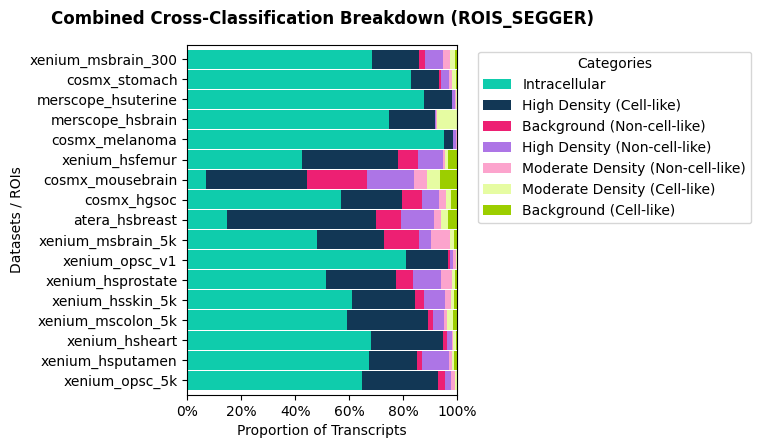

Saved normalized plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/rois_segger_Combined_Criteria_proportions.pdf


In [5]:
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Set font type for vector PDF/PS outputs to ensure editable text outlines
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

def plot_pipeline_stacked_bars_pct(global_counts, segmentation_filter, criterion_key, title, color_order=None, figsize=(6, 5), saving_path="."):
    """
    Extracts data for a specific segmentation method, normalizes the counts per dataset to 100%,
    and renders a horizontal stacked bar chart following the custom style specifications.
    Ensures the core axis panel keeps a fixed size regardless of legend footprint.
    """
    # 1. Filter out keys belonging to the requested segmentation method
    # (match the exact "<segmentation>/<sample>" prefix, not a plain string prefix,
    # so that e.g. "rois" does not also pick up "rois_proseg" / "rois_segger" keys)
    filtered_data = {
        k.split('/')[-1]: v[criterion_key] 
        for k, v in global_counts.items() 
        if k.split('/')[0] == segmentation_filter
    }
    
    if not filtered_data:
        print(f"No data found for segmentation method: {segmentation_filter} under {criterion_key}")
        return

    # 2. Convert to a structured DataFrame (Rows: Datasets, Columns: Categories)
    df_plot = pd.DataFrame(filtered_data).T.fillna(0)
    
    # 3. NORMALIZE: Divide each row by its row sum to represent relative proportions (%)
    df_plot_pct = df_plot.div(df_plot.sum(axis=1), axis=0)
    
    # Internal default color palette
    if color_order is None:
        plot_colors = [
            "#0FCCAC", "#ED2073", "#9CCE00", "#FC911D", 
            "#123755", "#790DB7", "#010101", "#F7C894", "#BCBCBC"
        ]
    else:
        plot_colors = color_order
    
    # Create the figure explicitly first
    fig = plt.figure(figsize=figsize)
    
    # Hardcode the relative structural position of the bar plot panel inside the figure canvas:
    # [left, bottom, width, height] as fractions of total figure width/height (from 0 to 1)
    # This guarantees the plot rectangle is ALWAYS exactly this size.
    ax = fig.add_axes([0.25, 0.15, 0.45, 0.7]) 
    
    # 4. Plot horizontal stacked bars on the explicitly sized axis
    df_plot_pct.plot(
        kind='barh',
        stacked=True,
        width=0.95,
        color=plot_colors[:df_plot_pct.shape[1]],
        ax=ax # Bind directly to our static geometry axis
    )
    
    # Formatting layout aesthetics
    ax.set_title(f"{title} ({segmentation_filter.upper()})", fontsize=12, weight='bold', pad=15)
    ax.set_xlabel('Proportion of Transcripts', fontsize=10)
    ax.set_ylabel('Datasets / ROIs', fontsize=10)
    ax.set_xlim(0, 1.0)
    
    # Display the X-axis marks as clean percentages
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(xmax=1.0))
    
    # Place legend cleanly outside of the plot box area
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Categories")
    
    # Save figure while ensuring bounding box scales OUTWARD around the legend
    output_filename = f"{segmentation_filter}_{criterion_key}_proportions.pdf"
    
    # CRITICAL: bbox_inches='tight' extends canvas bounding boxes dynamically 
    # instead of compressing the interior plot area.
    plt.savefig(
        os.path.join(saving_path, output_filename), 
        format='pdf', 
        bbox_inches='tight' 
    )
    plt.show() 
    plt.close() 
    print(f"Saved normalized plot to: {os.path.join(saving_path, output_filename)}")


# =====================================================================
# RUNNING THE PLOTS DOWNSTREAM OF YOUR LOOP
# =====================================================================

custom_hex_palette = ["#FF5733", "#33FF57", "#3357FF", "#F3FF33", "#FF33F3"]


for seg in segmentations:
    print(f"\nPlotting normalized maps for {seg}...")
    density_colors = ["#123755","#0FCCAC", "#ED2073", "#9CCE00", "#FC911D", 
    "#123755", "#790DB7", "#010101", "#F7C894", "#BCBCBC"]

    plot_pipeline_stacked_bars_pct(
        all_dataset_counts, 
        segmentation_filter=seg, color_order=density_colors,
        criterion_key='Crit1_Density', 
        title='Transcript Density Breakdown (Criterion 1)', 
        saving_path=saving_path
    )
    sim_colors = ["#123755", "#ED2073","#0FCCAC", "#9CCE00", "#FC911D"]
    
    plot_pipeline_stacked_bars_pct(
        all_dataset_counts, 
        segmentation_filter=seg, color_order=sim_colors,
        criterion_key='Crit2_Similarity', 
        title='RNA Local Similarity Breakdown (Criterion 2)',   
        saving_path=saving_path
    )
    all_colors = ["#0FCCAC", "#123755", "#ED2073", "#ad75e6",
                  "#fca4cd","#e6fca2","#9CCE00"]
    plot_pipeline_stacked_bars_pct(
        all_dataset_counts, 
        segmentation_filter=seg, 
        criterion_key='Combined_Criteria', 
        title='Combined Cross-Classification Breakdown', 
        color_order=all_colors,  
        saving_path=saving_path
    )

In [6]:
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

# Ensure editable text outlines for vector PDFs
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

def plot_paired_segmentation_comparison(global_counts, criterion_key, title, color_map=None,
                                         segmentation_order=("rois", "rois_proseg", "rois_segger"),
                                         figsize=(10, 6), saving_path="."):
    """
    Plots a horizontal stacked bar chart where each unique ROI/sample has one tightly
    grouped bar per segmentation method in `segmentation_order`. Segmentation types are
    indicated via a sub-legend (opacity-coded).
    """
    # 1. Structure the raw data into a MultiIndexed DataFrame
    records = []
    for unique_key, criteria_dict in global_counts.items():
        if '/' in unique_key and criterion_key in criteria_dict:
            seg, sample = unique_key.split('/', 1)
            if seg in segmentation_order:
                data_row = pd.Series(criteria_dict[criterion_key]).copy()
                data_row['segmentation_type'] = seg
                data_row['sample_roi'] = sample
                records.append(data_row)
                
    if not records:
        print(f"No data found to compare for criterion: {criterion_key}")
        return

    df_raw = pd.DataFrame(records).set_index(['sample_roi', 'segmentation_type'])
    
    # 2. Enforce explicit category sorting order
    # Define keywords/substring matches to map categories cleanly to your custom hierarchy
    def get_sort_weight(cat):
        cat_lower = str(cat).lower()
        if 'intracellular' in cat_lower:
            return 0
        elif 'high density' in cat_lower:
            return 1
        elif 'moderate density' in cat_lower:
            return 2
        elif 'cell-like' in cat_lower:  # Treat generic 'Cell-like' under moderate/high priority
            return 3
        elif 'non-cell-like' in cat_lower:
            return 4
        elif 'background' in cat_lower or 'unclassified' in cat_lower or 'unknown' in cat_lower:
            return 5
        else:
            return 6  # Fallback rule for any other text pairs
            
    # Sort columns based on the designated weight rule
    sorted_categories = sorted(df_raw.columns, key=get_sort_weight)
    df_raw = df_raw.reindex(columns=sorted_categories)
    
    # Normalize rows to 100% (proportions)
    df_pct = df_raw.div(df_raw.sum(axis=1), axis=0).fillna(0)
    
    # --- Dynamic Sample Sorting Based on Intracellular Values (Descending) ---
    # Find the exact column label that corresponds to "intracellular"
    intra_col = next((c for c in df_pct.columns if 'intracellular' in str(c).lower()), None)
    
    if intra_col is not None:
        # Group by sample_roi and take the mean intracellular value across all segmentation methods
        # Sorting is descending, so the highest proportions will end up where you want them
        sample_sorting_series = df_pct[intra_col].groupby('sample_roi').mean().sort_values(ascending=False)
        all_samples = sample_sorting_series.index.tolist()
    else:
        # Fallback to standard alphabetical sort if category missing
        all_samples = sorted(df_pct.index.get_level_values('sample_roi').unique())
    
    # 3. Handle categorical color assignment stably
    if color_map is None:
        default_colors = ["#123755", "#0FCCAC", "#ED2073", "#9CCE00", "#FC911D", "#790DB7", "#010101"]
        plot_colors = [default_colors[i % len(default_colors)] for i in range(len(sorted_categories))]
    else:
        # Fetch color mapped directly from our robust lookup dictionary, fallback if missing
        plot_colors = [color_map.get(cat, "#010101") for cat in sorted_categories]

    fig, ax = plt.subplots(figsize=figsize)
    
    # --- Tightened Spacing Parameters ---
    num_samples = len(all_samples)
    n_segs = len(segmentation_order)
    group_spacing = 0.6            # Tighter distance between center-to-center of different sample groups
    bar_width = (group_spacing * 0.8) / n_segs  # Scale to group_spacing so bars never overlap across groups, regardless of n_segs
    # Opacity step per segmentation method, following the original solid/0.75-alpha convention
    alphas = [1.0 - 0.25 * i for i in range(n_segs)]
    
    y_positions = [i * group_spacing for i in range(num_samples)]
    
    # Loop over each sample and each segmentation method to plot them
    for idx, sample in enumerate(all_samples):
        base_y = y_positions[idx]
        for s_idx, seg_name in enumerate(segmentation_order):
            y = base_y + (s_idx - (n_segs - 1) / 2) * bar_width

            if (sample, seg_name) in df_pct.index:
                row = df_pct.loc[(sample, seg_name)]
                left_offset = 0
                for col_idx, (cat, val) in enumerate(row.items()):
                    ax.barh(y, val, left=left_offset, height=bar_width, 
                            color=plot_colors[col_idx], alpha=alphas[s_idx], edgecolor='none')
                    left_offset += val

    # 4. Aesthetics & Label Formatting
    ax.set_title(title, fontsize=13, weight='bold', pad=20)
    ax.set_xlabel('Proportion of Transcripts', fontsize=10)
    ax.set_xlim(0, 1.0)
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(xmax=1.0))
    
    # Set Y-ticks cleanly without overlapping text
    ax.set_yticks(y_positions)
    ax.set_yticklabels(all_samples, fontsize=10)
    ax.set_ylabel('Datasets / ROIs', fontsize=10)
    
    # Completely remove background gridlines lines
    ax.grid(False)
    
    # 5. Dual-Legend System (Categories + Method Indicators)
    categories = df_pct.columns.tolist()
    cat_handles = [plt.Rectangle((0,0), 1, 1, color=plot_colors[i]) for i in range(len(categories))]
    legend_cat = ax.legend(cat_handles, categories, bbox_to_anchor=(1.05, 1), loc='upper left', title="Categories")
    
    method_handles = [
        plt.Rectangle((0,0), 1, 1, color='#555555', alpha=alphas[i]) for i in range(n_segs)
    ]
    legend_method = ax.legend(method_handles, list(segmentation_order), 
                              bbox_to_anchor=(1.05, 0.3), loc='upper left', title="Configuration")
    
    # Re-add the first legend back to the canvas manually
    ax.add_artist(legend_cat)
    
    # Save chart
    output_filename = f"paired_comparison_{criterion_key}.pdf"
    plt.savefig(
        os.path.join(saving_path, output_filename), 
        format='pdf', 
        bbox_inches='tight'
    )
    plt.show()
    plt.close()
    print(f"Saved optimized paired plot to: {os.path.join(saving_path, output_filename)}")

In [7]:
density_colors = ["#123755","#0FCCAC", "#ED2073", "#9CCE00", "#FC911D", "#790DB7", "#010101"]
sim_colors = ["#123755", "#ED2073","#0FCCAC", "#9CCE00", "#FC911D"]
all_colors = [ "#123755", "#ED2073","#0FCCAC","#ad75e6", "#fca4cd", "#e6fca2", "#9CCE00"]



Generating ordered paired segmentation analysis charts...


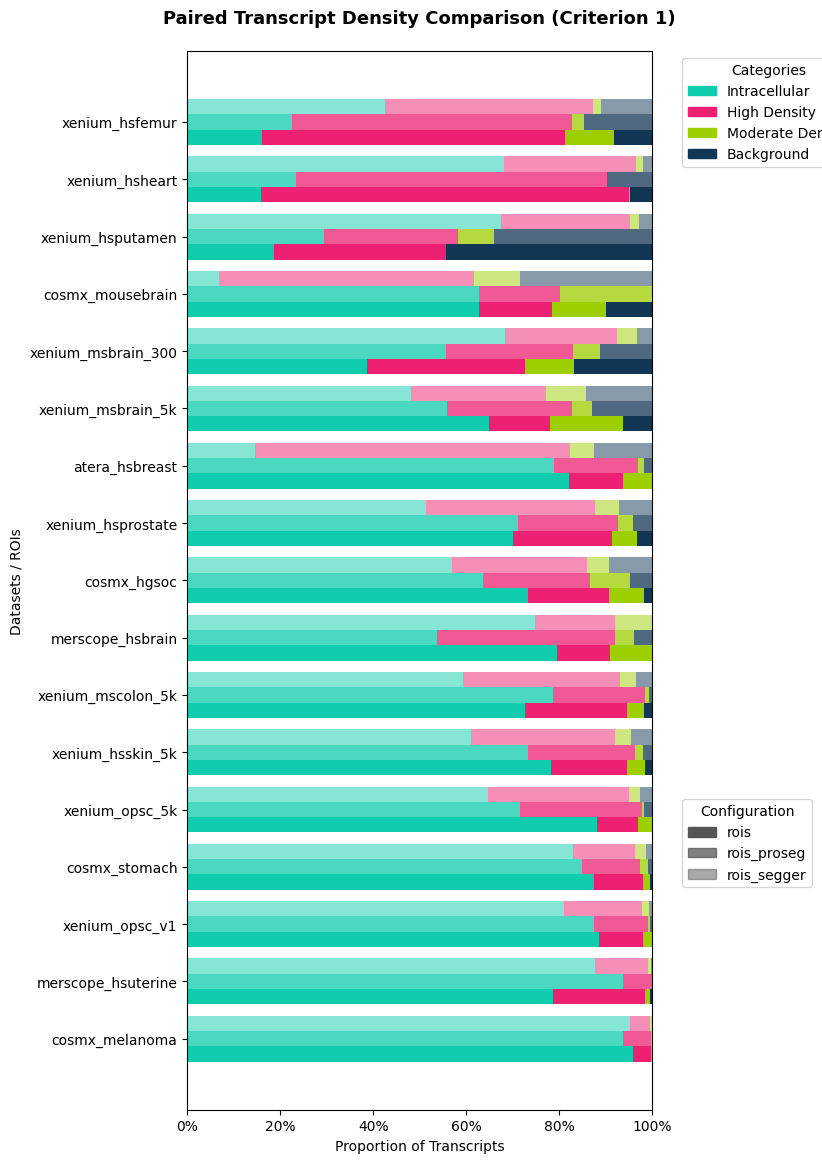

Saved optimized paired plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/paired_comparison_Crit1_Density.pdf


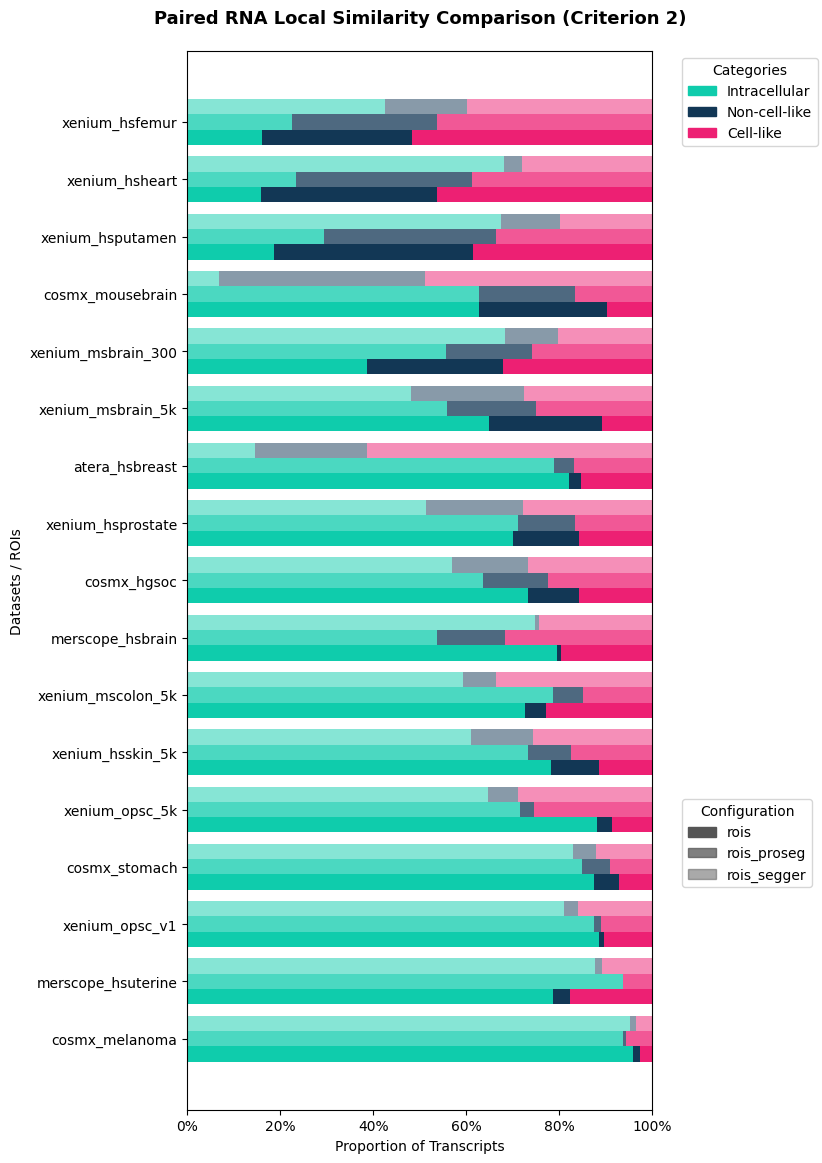

Saved optimized paired plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/paired_comparison_Crit2_Similarity.pdf


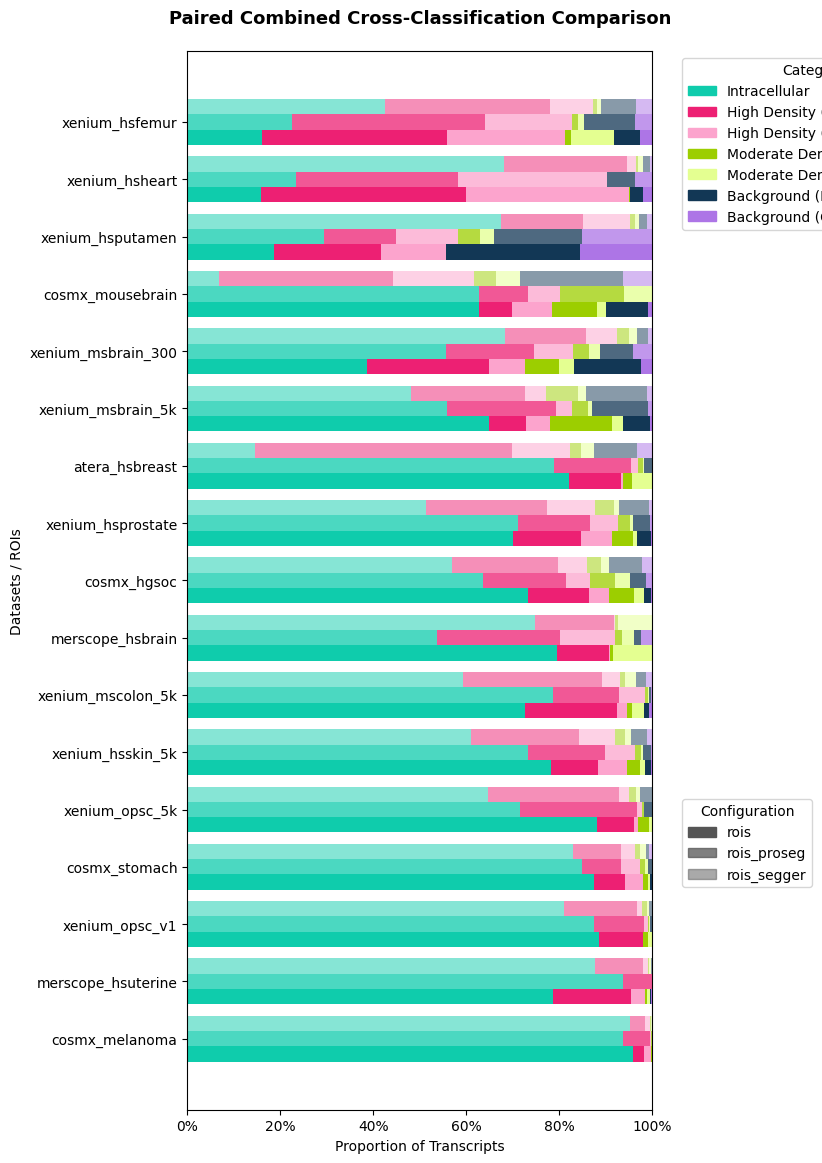

Saved optimized paired plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/paired_comparison_Combined_Criteria.pdf


In [8]:
# Create an explicit color mapping lookup dictionary across possible classification outputs
color_mapping = {
    # Intracellular
    "Intracellular": "#0FCCAC",
    
    # Criterion 1 Density Classes
    "High Density": "#ED2073",
    "Moderate Density": "#9CCE00",
    "Background": "#123755",
    
    # Criterion 2 Similarity Classes
    "Cell-like": "#ED2073",
    "Non-cell-like": "#123755",
    "Unclassified": "#010101",
    
    # Combined cross-class combinations (Example mappings based on string concats from your generator)
    "High Density (Cell-like)": "#ED2073",
    "High Density (Non-cell-like)": "#fca4cd",
    "Moderate Density (Cell-like)":  "#e4ff91",
    "Moderate Density (Non-cell-like)": "#9CCE00",
    "Background (Cell-like)": "#ad75e6",
    "Background (Non-cell-like)": "#123755",
    "Unknown": "#010101"
}

print("\nGenerating ordered paired segmentation analysis charts...")

# Subplot 1: Density Breakdown (Criterion 1)
plot_paired_segmentation_comparison(
    all_dataset_counts, 
    criterion_key='Crit1_Density', 
    title='Paired Transcript Density Comparison (Criterion 1)', 
    color_map=color_mapping,
    figsize=(6, 1 + len(all_dataset_counts)*0.25),
    saving_path=saving_path
)

# Subplot 2: Similarity Breakdown (Criterion 2)
plot_paired_segmentation_comparison(
    all_dataset_counts, 
    criterion_key='Crit2_Similarity', 
    title='Paired RNA Local Similarity Comparison (Criterion 2)', 
    color_map=color_mapping,
    figsize=(6, 1 + len(all_dataset_counts)*0.25),
    saving_path=saving_path
)

# Subplot 3: Combined Classifications
plot_paired_segmentation_comparison(
    all_dataset_counts, 
    criterion_key='Combined_Criteria', 
    title='Paired Combined Cross-Classification Comparison', 
    color_map=color_mapping,
    figsize=(6, 1 + len(all_dataset_counts)*0.25),
    saving_path=saving_path
)

# Analysis

In [9]:
import pandas as pd
import numpy as np

def report_absolute_and_relative_metrics(global_counts):
    """
    Computes absolute global percentages (out of All RNA) and within-uRNA percentages
    separating Cell-boundary samples from Nuclei-boundary samples.
    
    Returns:
    --------
    pd.DataFrame: A structured data summary table ideal for exporting to CSV/Excel.
    """
    # Nuclei-prior sample blacklist
    nuclei_samples = ['xenium_hsfemur', 'xenium_hsheart', 'xenium_hsputamen', 'xenium_msbrain_300']
    
    c1_records = []
    c2_records = []
    
    for unique_key, criteria_dict in global_counts.items():
        if '/' in unique_key:
            seg, sample = unique_key.split('/', 1)
            
            # Determine background prior cohort
            cohort_type = 'Nuclei-Prior' if sample in nuclei_samples else 'Cell-Boundary'
            
            if 'Crit1_Density' in criteria_dict:
                d = criteria_dict['Crit1_Density'].copy()
                d['seg'], d['sample'], d['cohort'] = seg, sample, cohort_type
                c1_records.append(d)
                
            if 'Crit2_Similarity' in criteria_dict:
                d = criteria_dict['Crit2_Similarity'].copy()
                d['seg'], d['sample'], d['cohort'] = seg, sample, cohort_type
                c2_records.append(d)

    df_c1 = pd.DataFrame(c1_records).set_index(['sample', 'seg', 'cohort']).fillna(0)
    df_c2 = pd.DataFrame(c2_records).set_index(['sample', 'seg', 'cohort']).fillna(0)
    
    # Storage list for compiling exportable data rows
    export_rows = []
    
    for cohort in ['Cell-Boundary', 'Nuclei-Prior']:
        print("=" * 85)
        print(f" COHORT GROUP: {cohort.upper()}")
        print("=" * 85)
        
        for seg_type in ['rois', 'rois_proseg', 'rois_segger']:
            print(f"\n  ▶ STRATEGY: [{seg_type.upper()}]")
            print("  " + "-" * 40)
            
            mean_intra, mean_urna = np.nan, np.nan
            
            # --- CRITERION 2: SIMILARITY ---
            if seg_type in df_c2.index.get_level_values('seg'):
                sub_c2 = df_c2.xs((seg_type, cohort), level=('seg', 'cohort'))
                
                if not sub_c2.empty:
                    pct_c2_abs = sub_c2.div(sub_c2.sum(axis=1), axis=0) * 100
                    intra_col = [c for c in pct_c2_abs.columns if 'intracellular' in c.lower()][0]
                    
                    mean_intra = pct_c2_abs[intra_col].mean()
                    mean_urna = 100.0 - mean_intra
                    
                    print(f"    [Global Baseline]:")
                    print(f"      • Intracellular Transcripts:  {mean_intra:.1f}% (of Total RNA)")
                    print(f"      • Total uRNA Pool:             {mean_urna:.1f}% (of Total RNA)")
                    print("\n    [Similarity - Criterion 2]:")
                    
                    uRNA_cols = [c for c in sub_c2.columns if 'intracellular' not in c.lower()]
                    pct_c2_rel = sub_c2[uRNA_cols].div(sub_c2[uRNA_cols].sum(axis=1), axis=0) * 100
                    
                    for col in uRNA_cols:
                        abs_val = pct_c2_abs[col].mean()
                        rel_val = pct_c2_rel[col].mean()
                        print(f"      - {col:<15} Absolute: {abs_val:>5.1f}% (of Total RNA)  |  Within uRNA: {rel_val:>5.1f}%")
                        
                        export_rows.append({
                            'Cohort': cohort, 'Strategy': seg_type, 'Criterion': 'Criterion 2 (Similarity)',
                            'Category': col, 'Mean_Pct_of_Total_RNA': round(abs_val, 2), 'Mean_Pct_within_uRNA': round(rel_val, 2)
                        })
            
            # --- CRITERION 1: DENSITY ---
            if seg_type in df_c1.index.get_level_values('seg'):
                sub_c1 = df_c1.xs((seg_type, cohort), level=('seg', 'cohort'))
                
                if not sub_c1.empty:
                    pct_c1_abs = sub_c1.div(sub_c1.sum(axis=1), axis=0) * 100
                    uRNA_cols = [c for c in sub_c1.columns if 'intracellular' not in c.lower()]
                    pct_c1_rel = sub_c1[uRNA_cols].div(sub_c1[uRNA_cols].sum(axis=1), axis=0) * 100
                    
                    print("\n    [Density - Criterion 1]:")
                    for col in uRNA_cols:
                        abs_val = pct_c1_abs[col].mean()
                        rel_val = pct_c1_rel[col].mean()
                        print(f"      - {col:<15} Absolute: {abs_val:>5.1f}% (of Total RNA)  |  Within uRNA: {rel_val:>5.1f}%")
                        
                        export_rows.append({
                            'Cohort': cohort, 'Strategy': seg_type, 'Criterion': 'Criterion 1 (Density)',
                            'Category': col, 'Mean_Pct_of_Total_RNA': round(abs_val, 2), 'Mean_Pct_within_uRNA': round(rel_val, 2)
                        })
            
            # Also append baseline context elements to tracking list
            if not np.isnan(mean_intra):
                export_rows.append({
                    'Cohort': cohort, 'Strategy': seg_type, 'Criterion': 'Global Context',
                    'Category': 'Intracellular Baseline', 'Mean_Pct_of_Total_RNA': round(mean_intra, 2), 'Mean_Pct_within_uRNA': np.nan
                })
            print("  " + "-" * 60)
        print("\n" + "=" * 85)

    return pd.DataFrame(export_rows)

# 1. Run and collect DataFrame output
summary_df = report_absolute_and_relative_metrics(all_dataset_counts)
summary_df.to_csv(os.path.join(saving_path,'percentages_across_samples.csv'))

 COHORT GROUP: CELL-BOUNDARY

  ▶ STRATEGY: [ROIS]
  ----------------------------------------
    [Global Baseline]:
      • Intracellular Transcripts:  78.6% (of Total RNA)
      • Total uRNA Pool:             21.4% (of Total RNA)

    [Similarity - Criterion 2]:
      - Non-cell-like   Absolute:   8.4% (of Total RNA)  |  Within uRNA:  34.4%
      - Cell-like       Absolute:  12.9% (of Total RNA)  |  Within uRNA:  65.6%

    [Density - Criterion 1]:
      - Background      Absolute:   2.0% (of Total RNA)  |  Within uRNA:   6.3%
      - High Density    Absolute:  14.0% (of Total RNA)  |  Within uRNA:  70.6%
      - Moderate Density Absolute:   5.5% (of Total RNA)  |  Within uRNA:  23.2%
  ------------------------------------------------------------

  ▶ STRATEGY: [ROIS_PROSEG]
  ----------------------------------------
    [Global Baseline]:
      • Intracellular Transcripts:  74.5% (of Total RNA)
      • Total uRNA Pool:             25.5% (of Total RNA)

    [Similarity - Criterion 2]

# Cell-like vs density

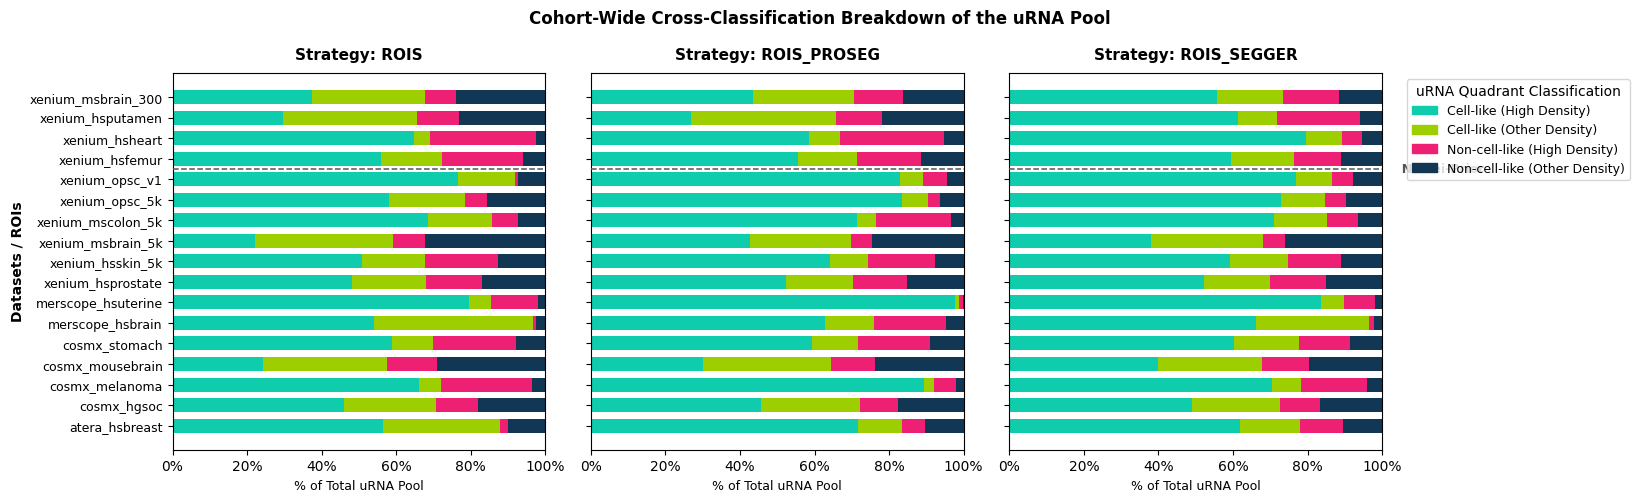

Saved layout securely to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/urna_quadrant_composition.pdf


In [10]:
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Ensure editable text outlines for vector PDFs
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

def plot_urna_quadrant_composition(global_counts, colors=None, strategies=("rois", "rois_proseg", "rois_segger"), saving_path="."):
    """
    Plots a 100% stacked horizontal bar chart breaking down the total uRNA pool 
    into 4 mutually exclusive quadrants based on Density and Local Similarity.
    """
    nuclei_samples = ['xenium_hsfemur', 'xenium_hsheart', 'xenium_hsputamen', 'xenium_msbrain_300']
    records = []
    
    for unique_key, criteria_dict in global_counts.items():
        if '/' in unique_key and 'Combined_Criteria' in criteria_dict:
            seg, sample = unique_key.split('/', 1)
            cohort_type = 'Nuclei-Prior' if sample in nuclei_samples else 'Cell-Boundary'
            raw_data = criteria_dict['Combined_Criteria']
            
            # Group into your 4 exact quadrants using case-insensitive matches
            c_hd = sum(v for k, v in raw_data.items() if 'high' in k.lower() and 'cell-like' in k.lower())
            c_other = sum(v for k, v in raw_data.items() if ('mod' in k.lower() or 'back' in k.lower()) and 'cell-like' in k.lower())
            nc_hd = sum(v for k, v in raw_data.items() if 'high' in k.lower() and 'non-cell' in k.lower())
            nc_other = sum(v for k, v in raw_data.items() if ('mod' in k.lower() or 'back' in k.lower()) and 'non-cell' in k.lower())
            
            records.append({
                'sample': sample, 'seg': seg, 'cohort': cohort_type,
                'Cell-like (High Density)': c_hd,
                'Cell-like (Other Density)': c_other,
                'Non-cell-like (High Density)': nc_hd,
                'Non-cell-like (Other Density)': nc_other
            })
            
    df = pd.DataFrame(records)
    if df.empty:
        print("No combined criteria data found.")
        return
        
    df = df.sort_values(by=['cohort', 'sample'])
    unique_samples = df['sample'].unique()
    
    # Define categories and clear visual color coding
    categories = [
        'Cell-like (High Density)', 
        'Cell-like (Other Density)', 
        'Non-cell-like (High Density)', 
        'Non-cell-like (Other Density)'
    ]
    if colors is None:
        # High-density variants are bold; Low-density/other variants are lighter/muted
        colors = ["#0FCCAC", "#9CCE00", "#ED2073", "#123755"] 

    strategies = list(strategies)
    n_strategies = len(strategies)
    fig, axes = plt.subplots(1, n_strategies, figsize=(5.5 * n_strategies, 1 + len(unique_samples) * 0.24), sharey=True)
    if n_strategies == 1:
        axes = [axes]
    y_positions = np.arange(len(unique_samples))
    sample_to_y = {s: i for i, s in enumerate(unique_samples)}
    
    for ax_idx, seg_type in enumerate(strategies):
        ax = axes[ax_idx]
        sub_df = df[df['seg'] == seg_type].set_index('sample')
        
        # Soft scannability guidelines
        for y_val in y_positions:
            ax.axhline(y_val, color='#F5F5F5', linestyle='-', linewidth=0.8, zorder=0)
            
        for sample_name, y_pos in sample_to_y.items():
            if sample_name in sub_df.index:
                row = sub_df.loc[sample_name]
                total_urna = row[categories].sum()
                
                if total_urna > 0:
                    # Normalize everything to 100% of the uRNA pool
                    pcts = (row[categories] / total_urna) * 100
                    
                    left_offset = 0
                    for cat_idx, cat in enumerate(categories):
                        val = pcts[cat]
                        ax.barh(y_pos, val, left=left_offset, height=0.68, 
                                color=colors[cat_idx], edgecolor='none', zorder=2)
                        left_offset += val
                else:
                    ax.text(50, y_pos, 'Empty uRNA Pool', ha='center', va='center', 
                            fontsize=8, color='#888888', fontstyle='italic')
                            
        ax.set_title(f"Strategy: {seg_type.upper()}", fontsize=11, weight='bold', pad=10)
        ax.set_xlabel('% of Total uRNA Pool', fontsize=9)
        ax.set_xlim(0, 100)
        ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(xmax=100))
        ax.grid(False)
        
        # Draw cohort boundary break
        cohort_boundaries = df.drop_duplicates(subset=['sample']).reset_index()
        split_idx = cohort_boundaries[cohort_boundaries['cohort'] == 'Nuclei-Prior'].index
        if len(split_idx) > 0:
            divider_y = split_idx[0] - 0.5
            ax.axhline(divider_y, color='#555555', linestyle='--', linewidth=1.1, zorder=3)
            if ax_idx == n_strategies - 1:
                ax.text(103, divider_y, '  Nuclei-Prior', va='center', fontsize=9, weight='bold', color='#555555')

    # Axis Labels & Global Legend Setup
    axes[0].set_yticks(y_positions)
    axes[0].set_yticklabels(unique_samples, fontsize=9)
    axes[0].set_ylabel('Datasets / ROIs', fontsize=10, weight='bold')
    
    handles = [plt.Rectangle((0,0), 1, 1, color=colors[i]) for i in range(len(categories))]
    axes[-1].legend(handles, categories, title="uRNA Quadrant Classification", 
                  bbox_to_anchor=(1.05, 1.0), loc='upper left', fontsize=9)
    
    fig.suptitle('Cohort-Wide Cross-Classification Breakdown of the uRNA Pool', 
                 fontsize=12, weight='bold', y=0.98)
    
    plt.tight_layout()
    output_path = os.path.join(saving_path, "urna_quadrant_composition.pdf")
    plt.savefig(output_path, format='pdf', bbox_inches='tight')
    plt.show()
    plt.close()
    print(f"Saved layout securely to: {output_path}")

# Run layout generation tool
plot_urna_quadrant_composition(all_dataset_counts, saving_path=saving_path)

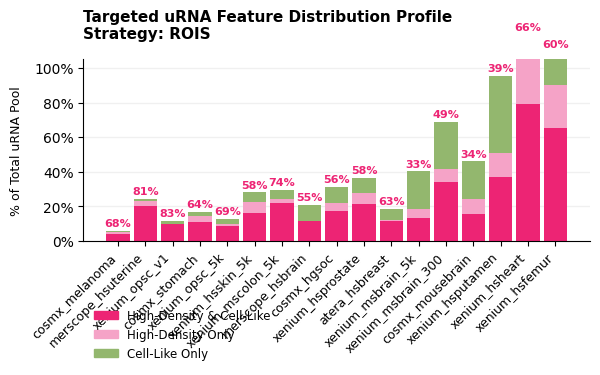

Saved vertical composition plot with purity labels to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/uRNA_positive_features_vertical_rois.pdf


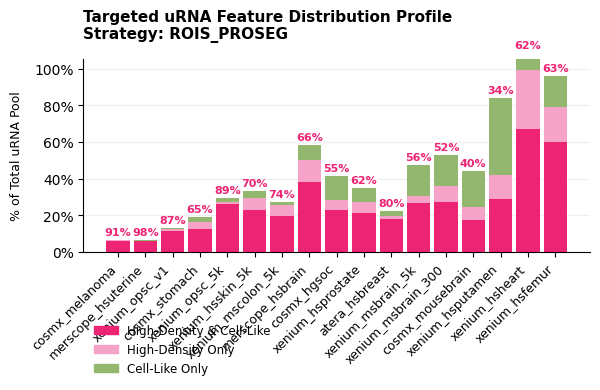

Saved vertical composition plot with purity labels to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/uRNA_positive_features_vertical_rois_proseg.pdf


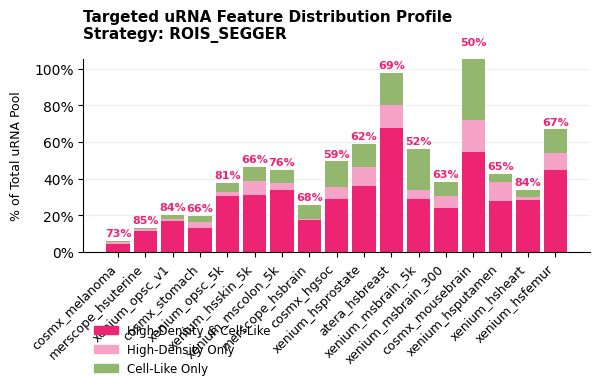

Saved vertical composition plot with purity labels to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/uRNA_positive_features_vertical_rois_segger.pdf


In [11]:
import os
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Ensure editable text outlines for vector PDFs
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

def plot_selective_hd_composition_vertical(global_counts, colors=None, strategies=("rois", "rois_proseg", "rois_segger"), saving_path="."):
    """
    Generates independent vertical stacked bar plots for each segmentation method in `strategies`.
    Plots only the positive categories as a % of the total uRNA pool.
    The double-negative background is excluded, so bars will not reach 100%.
    """
    strategies = list(strategies)

    # -------------------------------------------------------------------------
    # 1. First Pass: Compute sorting order based on Intracellular means
    # -------------------------------------------------------------------------
    sorting_records = []
    for unique_key, criteria_dict in global_counts.items():
        if '/' in unique_key and 'Crit2_Similarity' in criteria_dict:
            seg, sample = unique_key.split('/', 1)
            if seg in strategies:
                data_row = pd.Series(criteria_dict['Crit2_Similarity']).copy()
                data_row['seg'] = seg
                data_row['sample'] = sample
                sorting_records.append(data_row)
                
    if not sorting_records:
        print("Could not find baseline data to establish sorting order.")
        return
        
    df_sort = pd.DataFrame(sorting_records).set_index(['sample', 'seg']).fillna(0)
    df_sort_pct = df_sort.div(df_sort.sum(axis=1), axis=0).fillna(0)
    
    intra_col = next((c for c in df_sort_pct.columns if 'intracellular' in str(c).lower()), None)
    
    if intra_col is not None:
        sample_sorting_series = df_sort_pct[intra_col].groupby('sample').mean().sort_values(ascending=False)
        all_samples = sample_sorting_series.index.tolist()
    else:
        all_samples = sorted(df_sort_pct.index.get_level_values('sample').unique())

    # -------------------------------------------------------------------------
    # 2. Second Pass: Extract Positive Categories Relative to Total uRNA
    # -------------------------------------------------------------------------
    records = []
    for unique_key, criteria_dict in global_counts.items():
        if '/' in unique_key and 'Combined_Criteria' in criteria_dict:
            seg, sample = unique_key.split('/', 1)
            raw_data = criteria_dict['Combined_Criteria']
            
            # Absolute total uRNA across all 4 quadrants to use as a stable denominator
            total_uRNA_pool = sum(raw_data.values())
            
            # Extract raw quadrant values
            hd_cell = sum(v for k, v in raw_data.items() if 'high' in k.lower() and 'cell-like' in k.lower())
            hd_non_cell = sum(v for k, v in raw_data.items() if 'high' in k.lower() and 'non-cell' in k.lower())
            non_hd_cell = sum(v for k, v in raw_data.items() if ('mod' in k.lower() or 'back' in k.lower()) and 'cell-like' in k.lower())
            
            # Convert to absolute percentages of the entire uRNA population
            pct_double_positive = (hd_cell / total_uRNA_pool * 100) if total_uRNA_pool > 0 else 0
            pct_hd_only = (hd_non_cell / total_uRNA_pool * 100) if total_uRNA_pool > 0 else 0
            pct_cell_only = (non_hd_cell / total_uRNA_pool * 100) if total_uRNA_pool > 0 else 0
            
            records.append({
                'sample': sample, 'seg': seg,
                'High-Density & Cell-Like': pct_double_positive,
                'High-Density Only': pct_hd_only,
                'Cell-Like Only': pct_cell_only
            })
            
    df_metrics = pd.DataFrame(records)
    if df_metrics.empty:
        print("No combined criteria data found to visualize.")
        return

    # -------------------------------------------------------------------------
    # 3. Third Pass: Plot Generation (Vertical Bars, Compact Spacing)
    # -------------------------------------------------------------------------
    categories = ['High-Density & Cell-Like', 'High-Density Only', 'Cell-Like Only']
    
    if colors is None:
        colors = ["#ed2474", "#f5a3c7", "#93b76e"] 
        
    bar_width = 0.60        # Substantial bar width profile
    group_spacing = 0.7     # Compressed width stepping sequence
    
    num_samples = len(all_samples)
    x_positions = [i * group_spacing for i in range(num_samples)]
    sample_to_x = {s: x_positions[i] for i, s in enumerate(all_samples)}
    
    for seg_type in strategies:
        sub_df = df_metrics[df_metrics['seg'] == seg_type].set_index('sample')
        if sub_df.empty:
            continue
            
        # Re-scaled figure setup to optimize a vertical grid layout
        fig, ax = plt.subplots(figsize=(1.0 + num_samples * 0.30, 4.5))
        
        # Soft scannability alignment lines (Y-axis gridlines)
        ax.set_axisbelow(True)
        ax.yaxis.grid(True, color='#F0F0F0', linestyle='-', linewidth=1.0, zorder=0)
            
        for sample_name, x_pos in sample_to_x.items():
            if sample_name in sub_df.index:
                row = sub_df.loc[sample_name]
                
                # Render the vertical segments
                bottom_offset = 0
                for cat_idx, cat in enumerate(categories):
                    val = row[cat]
                    ax.bar(x_pos, val, bottom=bottom_offset, width=bar_width, 
                           color=colors[cat_idx], edgecolor='none', zorder=2)
                    bottom_offset += val
                
                # Compute % of double category over the sum of the three visible positive categories
                three_cat_total = row[categories].sum()
                if three_cat_total > 0:
                    pct_double_over_three = (row['High-Density & Cell-Like'] / three_cat_total) * 100
                    
                    # Overlay exact calculated percentage text in hot pink right on top of the stacked bar
                    ax.text(x_pos, bottom_offset + 1.5, f"{int(round(pct_double_over_three))}%", 
                            ha='center', va='bottom', fontsize=8, weight='bold', color=colors[0], zorder=4)

        # Layout Dressing
        ax.set_title(f"Targeted uRNA Feature Distribution Profile\nStrategy: {seg_type.upper()}", 
                     fontsize=11, weight='bold', pad=15, loc='left')
        ax.set_ylabel('% of Total uRNA Pool', fontsize=9, labelpad=8)
        ax.set_ylim(0, 105) # Expanded slightly up to accommodate textual labels safely
        ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(xmax=100))
        
        ax.set_xticks(x_positions)
        ax.set_xticklabels(all_samples, fontsize=9, rotation=45, ha='right')
        ax.grid(False, axis='x')
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        
        # Free-floating legend underneath the chart
        handles = [plt.Rectangle((0,0), 1, 1, color=colors[i]) for i in range(len(categories))]
        ax.legend(handles, categories, loc='upper left', bbox_to_anchor=(0.0, -0.32), frameon=False, fontsize=8.5)
        
        plt.tight_layout()
        
        output_path = os.path.join(saving_path, f"uRNA_positive_features_vertical_{seg_type}.pdf")
        plt.savefig(output_path, format='pdf', bbox_inches='tight')
        plt.show()
        plt.close()
        print(f"Saved vertical composition plot with purity labels to: {output_path}")

# Run layout script
plot_selective_hd_composition_vertical(all_dataset_counts, saving_path=saving_path)

## Low-to-medium density, non-cell-like uRNA ("background" uRNA)


In [12]:
import numpy as np
import pandas as pd

# "Low-to-medium density, non-cell-like" uRNA = everything in the Combined_Criteria
# classification that is NOT Intracellular, NOT High Density, and NOT Cell-like,
# i.e. (Moderate Density OR Background) AND Non-cell-like.
nuclei_samples = ['xenium_hsfemur', 'xenium_hsheart', 'xenium_hsputamen', 'xenium_msbrain_300']

low_med_noncell_records = []
for unique_key, criteria_dict in all_dataset_counts.items():
    if '/' not in unique_key or 'Combined_Criteria' not in criteria_dict:
        continue
    seg, sample = unique_key.split('/', 1)
    cohort_type = 'Nuclei-Prior' if sample in nuclei_samples else 'Cell-Boundary'
    raw_data = criteria_dict['Combined_Criteria']

    total_urna = sum(v for k, v in raw_data.items() if 'intracellular' not in k.lower())
    if total_urna == 0:
        continue

    low_med_noncell = sum(
        v for k, v in raw_data.items()
        if ('moderate' in k.lower() or 'background' in k.lower()) and 'non-cell-like' in k.lower()
    )
    pct_of_urna = (low_med_noncell / total_urna) * 100

    low_med_noncell_records.append({
        'seg': seg, 'sample': sample, 'cohort': cohort_type,
        'pct_low_to_medium_density_noncelllike_of_uRNA': pct_of_urna
    })

df_low_med_noncell = pd.DataFrame(low_med_noncell_records)

# Report per segmentation strategy, restricted to the default multimodal (Cell-Boundary) cohort
seg_name_map = {"rois": "def", "rois_proseg": "proseg", "rois_segger": "segger"}
summary_rows = []
for seg in ['rois', 'rois_proseg', 'rois_segger']:
    sub = df_low_med_noncell[(df_low_med_noncell['seg'] == seg) & (df_low_med_noncell['cohort'] == 'Cell-Boundary')]
    vals = sub['pct_low_to_medium_density_noncelllike_of_uRNA']
    if len(vals) == 0:
        continue
    summary_rows.append({
        'segmentation': seg_name_map.get(seg, seg),
        'n_samples': len(vals),
        'mean': vals.mean(),
        'std': vals.std(),
        'max': vals.max(),
        'min': vals.min(),
    })

low_med_noncell_summary = pd.DataFrame(summary_rows)
csv_out_path = os.path.join(saving_path, 'low_to_medium_density_noncelllike_uRNA_stats.csv')
low_med_noncell_summary.to_csv(csv_out_path, index=False)
print(f"Saved low-to-medium density, non-cell-like uRNA summary stats to: {csv_out_path}")

low_med_noncell_summary


Saved low-to-medium density, non-cell-like uRNA summary stats to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/general/low_to_medium_density_noncelllike_uRNA_stats.csv


,segmentation,n_samples,mean,std,max,min
0,def,13,18.631416,16.914255,54.427457,2.409186
1,proseg,13,13.730438,12.070622,36.790512,0.232699
2,segger,13,14.543026,10.797854,38.466229,2.114162
